## prev

In [26]:
%load_ext autoreload
%autoreload 2
import numpy as np
import D4CMPP_TLC
import SSC
from rdkit import Chem
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
# # sum_contribution model
# CLI_segment = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("CLI_segment_sum_contribution_C_paper_Rf_620_20260711_171320")
# BLI_segment = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("BLI_segment_sum_contribution_C_paper_Rf_620_20260711_154039")


CLI_segment = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("CLI_segment_attention_simple_C_paper_Rf_620_20260627_084202")
BLI_segment = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("BLI_segment_attention_simple_C_paper_Rf_620_20260627_084209")


# CLI_segment = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("CLI_segment_sum_contribution_normalized_C_paper_Rf_620_20260805_105456")
# BLI_segment = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3("BLI_segment_sum_contribution_normalized_C_paper_Rf_620_20260804_211357")


founded model: ./_Models/CLI_segment_attention_simple_C_paper_Rf_620_20260627_084202
Device: cuda
#params: 204131
Loading params from ./_Models/CLI_segment_attention_simple_C_paper_Rf_620_20260627_084202/final.pth
Sculptor Index: (6, 2, 0)
founded model: ./_Models/BLI_segment_attention_simple_C_paper_Rf_620_20260627_084209
Device: cuda
#params: 204131
Loading params from ./_Models/BLI_segment_attention_simple_C_paper_Rf_620_20260627_084209/final.pth
Sculptor Index: (6, 2, 0)


In [67]:
BLI_segment.get_score("Brc1ccc(-n2ccc3cccnc32)cc1",
          "CCCCCC",
          "CCOC(C)=O",
          0,
          1)

Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].


{'y': array([[-0.21729365]], dtype=float32),
 'subgroup_contributions': array([[ 0.10222553],
        [-0.14570971],
        [-0.17380947]], dtype=float32),
 'subgroup_size': array([[3]], dtype=int32)}

In [68]:
########## BLI 그림, 분자 1개 개별확인 ##########

score = visualize_segment_attention2(
    BLI_segment,
    "Brc1ccc(-n2ccc3cccnc32)cc1",
    "CCCCCC",
    "CCOC(C)=O",
    0.0,
    1.0,
    ratio=True,
)

Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].


frag,frag_smiles,atoms,subgroup_contributions,normalized
0,*Br,[0],0.102226,0.101871
1,c1cnc2nccc2c1,"[5, 6, 7, 8, 9, 10, 11, 12, 13]",-0.14571,-0.144687
2,c1ccccc1,"[1, 2, 3, 4, 14, 15]",-0.173809,-0.172080


In [12]:
#수정, 원본 후
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import HTML, display
import html
import numpy as np


def _as_1d_score(score_value):
    return np.asarray(score_value, dtype=float).reshape(-1)


def _fragment_atom_indices(fragment):
    return [int(a) for a in fragment.atoms]


def _subgroup_scores_to_atom_scores(mol, fragments, subgroup_scores):
    atom_values = {i: [] for i in range(mol.GetNumAtoms())}

    for fragment, score_value in zip(fragments, subgroup_scores):
        for atom_idx in _fragment_atom_indices(fragment):
            atom_values[atom_idx].append(float(score_value))

    return {
        atom_idx: float(np.mean(values))
        for atom_idx, values in atom_values.items()
        if values
    }
# 이겅

def _blue_white_red(score_value, vmin, vmax):
    max_val = max(abs(vmin), abs(vmax))
    
    if np.isclose(max_val, 0.0):
        return (0.95, 0.95, 0.95)

    new_vmin= -max_val
    new_vmax = max_val

    t = float((score_value - new_vmin) / (new_vmax - new_vmin))
    t = min(max(t, 0.0), 1.0)

    if t < 0.5:
        # blue -> white
        u = t / 0.5
        return (u, u, 1.0)

    # white -> red
    u = (t - 0.5) / 0.5
    return (1.0, 1.0 - u, 1.0 - u)


def _draw_attention_svg(smiles, fragments, subgroup_scores, title, vmin, vmax, width=360, height=280):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid molecule SMILES: {smiles}")

    mol = Chem.Mol(mol)
    atom_scores = _subgroup_scores_to_atom_scores(mol, fragments, subgroup_scores)
    highlight_atoms = list(atom_scores.keys())
    highlight_colors = {
        atom_idx: _blue_white_red(atom_scores[atom_idx], vmin, vmax)
        for atom_idx in highlight_atoms
    }
    highlight_radii = {
        atom_idx: 0.32 + 0.28 * abs((atom_scores[atom_idx] - vmin) / (vmax - vmin))
        if not np.isclose(vmin, vmax) else 0.35
        for atom_idx in highlight_atoms
    }

    drawer = rdMolDraw2D.MolDraw2DSVG(width, height)
    opts = drawer.drawOptions()
    opts.addAtomIndices = True
    drawer.DrawMolecule(
        mol,
        legend=title,
        highlightAtoms=highlight_atoms,
        highlightAtomColors=highlight_colors,
        highlightAtomRadii=highlight_radii,
    )
    drawer.FinishDrawing()
    return drawer.GetDrawingText().replace("svg:", "")

def _score_table_html(fragments, subgroup_scores, score_key, eluent_smiles=None, norm_values=None):
    rows = []
    if eluent_smiles is not None:
        rows.append(
            f"<div style='margin: 6px 0 8px 0;'><b>eluent smiles</b>: "
            f"<code>{html.escape(str(eluent_smiles))}</code></div>"
        )

    rows.append("<table style='border-collapse: collapse; font-size: 12px;'>")
    
    # 헤더 생성 (norm_values가 있으면 normalized 추가)
    header_html = (
        "<tr>"
        "<th style='text-align:right; padding:2px 8px;'>frag</th>"
        "<th style='text-align:left; padding:2px 8px;'>frag_smiles</th>"
        "<th style='text-align:left; padding:2px 8px;'>atoms</th>"
        f"<th style='text-align:right; padding:2px 8px;'>{html.escape(score_key)}</th>"
    )
    if norm_values is not None:
        header_html += "<th style='text-align:right; padding:2px 8px; color: #4a90e2;'>normalized</th>"
    header_html += "</tr>"
    rows.append(header_html)
    
    # 데이터 행 생성
    for idx, (fragment, score_value) in enumerate(zip(fragments, subgroup_scores)):
        row_html = (
            "<tr>"
            f"<td style='text-align:right; padding:2px 8px;'>{idx}</td>"
            f"<td style='padding:2px 8px;'><code>{html.escape(str(fragment.smiles))}</code></td>"
            f"<td style='padding:2px 8px;'>{_fragment_atom_indices(fragment)}</td>" # 원래 함수 유지
            f"<td style='text-align:right; padding:2px 8px;'>{float(score_value):.6g}</td>"
        )
        if norm_values is not None:
            # tanh 변환된 값은 소수점 6자리 고정 포맷으로 출력
            row_html += f"<td style='text-align:right; padding:2px 8px; font-weight:bold; color: #4a90e2;'>{float(norm_values[idx]):.6f}</td>"
        row_html += "</tr>"
        rows.append(row_html)
        
    rows.append("</table>")
    return "\n".join(rows)


def _attention_keys(score, ratio=False):
    if "attn1" in score and "attn2" in score:
        keys = ("attn1_ratio", "attn2_ratio") if ratio else ("attn1", "attn2")
        missing = [key for key in keys if key not in score]
        if missing:
            raise KeyError(f"Missing score key(s): {missing}. Available keys: {list(score.keys())}")
        return list(keys)

    if ratio and "attn_ratio" in score:
        return ["attn_ratio"]
    if "attn" in score:
        # Some BLI segment models already fold the eluent ratio into a single attn value.
        return ["attn"]

    expected = "attn_ratio" if ratio else "attn"
    raise KeyError(f"Missing score key: {expected}. Available keys: {list(score.keys())}")


def visualize_segment_attention(
    analyzer,
    smiles,
    eluent1_smiles,
    eluent2_smiles,
    ratio1,
    ratio2,
    *,
    ratio=False,
    score=None,
    width=360,
    height=280,
):
    """Visualize subgroup attention returned by analyzer.get_score().

    ratio=False uses attn or attn1/attn2.
    ratio=True uses attn_ratio or attn1_ratio/attn2_ratio when present.
    Single-attn BLI outputs may only have attn because ratio is already part of the model input.
    """
    if score is None:
        score = analyzer.get_score(smiles, eluent1_smiles, eluent2_smiles, ratio1, ratio2)

    fragments = analyzer.get_fragment(smiles)
    keys = _attention_keys(score, ratio=ratio)
    score_arrays = [_as_1d_score(score[key]) for key in keys]

    expected_size = len(fragments)
    for key, values in zip(keys, score_arrays):
        if len(values) != expected_size:
            raise ValueError(
                f"{key} length ({len(values)}) does not match fragment count ({expected_size})."
            )

    all_values = np.concatenate(score_arrays)
    vmin = float(np.min(all_values))
    vmax = float(np.max(all_values))

    combined_eluent_label = (
        f"{eluent1_smiles} ({ratio1:g}) + {eluent2_smiles} ({ratio2:g})"
    )
    eluent_by_key = {
        "attn": combined_eluent_label,
        "attn_ratio": combined_eluent_label,
        "attn1": eluent1_smiles,
        "attn1_ratio": eluent1_smiles,
        "attn2": eluent2_smiles,
        "attn2_ratio": eluent2_smiles,
    }

    panels = []
    for key, values in zip(keys, score_arrays):
        eluent_smiles = eluent_by_key.get(key)
        title = key if eluent_smiles is None else f"{key}: {eluent_smiles}"
        svg = _draw_attention_svg(
            smiles,
            fragments,
            values,
            title=title,
            vmin=vmin,
            vmax=vmax,
            width=width,
            height=height,
        )
        table = _score_table_html(fragments, values, key, eluent_smiles=eluent_smiles)
        panels.append(
            "<div style='display:inline-block; vertical-align:top; margin:0 18px 18px 0;'>"
            f"{svg}"
            f"{table}"
            "</div>"
        )

    caption = (
        "<div style='margin-bottom:8px; font-size:13px;'>"
        "Color scale: low attention = blue, high attention = red. "
        f"Range: {vmin:.6g} to {vmax:.6g}."
        "</div>"
    )
    display(HTML(caption + "<div>" + "\n".join(panels) + "</div>"))
    return score


def _contribution_keys(score, ratio=False):
    if "subgroup_contribution1" in score and "subgroup_contribution2" in score:
        keys = (
            ("ratio_weighted_contribution1", "ratio_weighted_contribution2")
            if ratio else
            ("subgroup_contribution1", "subgroup_contribution2")
        )
        missing = [key for key in keys if key not in score]
        if missing:
            raise KeyError(f"Missing score key(s): {missing}. Available keys: {list(score.keys())}")
        return list(keys)

    if "subgroup_contributions" in score:
        # BLI sum-contribution output already uses the ratio-weighted bulk eluent representation.
        return ["subgroup_contributions"]

    raise KeyError(
        "Missing sum-contribution score keys. "
        f"Available keys: {list(score.keys())}"
    )
    
    
def visualize_segment_attention2(
    analyzer,
    smiles,
    eluent1_smiles,
    eluent2_smiles,
    ratio1,
    ratio2,
    *,
    ratio=False,
    score=None,
    width=360,
    height=280,
):
    if score is None:
        score = analyzer.get_score(smiles, eluent1_smiles, eluent2_smiles, ratio1, ratio2)

    fragments = analyzer.get_fragment(smiles)
    keys = _contribution_keys(score, ratio=ratio)
    score_arrays = [_as_1d_score(score[key]) for key in keys]

    expected_size = len(fragments)
    for key, values in zip(keys, score_arrays):
        if len(values) != expected_size:
            raise ValueError(
                f"{key} length ({len(values)}) does not match fragment count ({expected_size})."
            )

    all_values = np.concatenate(score_arrays)
    vmin = float(np.min(all_values))
    vmax = float(np.max(all_values))

    combined_eluent_label = (
        f"{eluent1_smiles} ({ratio1:g}) + {eluent2_smiles} ({ratio2:g})"
    )
    eluent_by_key = {
        "subgroup_contributions": combined_eluent_label,
        "subgroup_contribution1": eluent1_smiles,
        "ratio_weighted_contribution1": eluent1_smiles,
        "subgroup_contribution2": eluent2_smiles,
        "ratio_weighted_contribution2": eluent2_smiles,
    }

    panels = []
    for key, values in zip(keys, score_arrays):
        eluent_smiles = eluent_by_key.get(key)
        title = key if eluent_smiles is None else f"{key}: {eluent_smiles}"
        
        # 원본 분자 SVG 드로잉 (컬러 스케일 기준은 기존 원본 유지)
        svg = _draw_attention_svg(
            smiles,
            fragments,
            values,
            title=title,
            vmin=vmin,
            vmax=vmax,
            width=width,
            height=height,
        )
        
        # 요청하신 3가지 특정 키값일 때만 tanh 정규화 적용
        target_keys = ["subgroup_contributions", "ratio_weighted_contribution1", "ratio_weighted_contribution2"]
        if key in target_keys:
            # 💡 tanh 함수를 사용하여 [-1, 1] 범위로 정규화
            norm_values = np.tanh(values)
        else:
            norm_values = None

        # 수정된 테이블 함수 호출 (norm_values 전달)
        table = _score_table_html(
            fragments, 
            values, 
            key, 
            eluent_smiles=eluent_smiles, 
            norm_values=norm_values
        )
        
        panels.append(
            "<div style='display:inline-block; vertical-align:top; margin:0 18px 18px 0;'>"
            f"{svg}"
            f"{table}"
            "</div>"
        )

    caption = (
        "<div style='margin-bottom:8px; font-size:13px;'>"
        "Color scale: low contribution = blue, high contribution = red. "
        f"Range: {vmin:.6g} to {vmax:.6g}."
        "</div>"
    )
    display(HTML(caption + "<div>" + "\n".join(panels) + "</div>"))
    return score

# Backward-compatible alias
visualiae_segment_attention2 = visualize_segment_attention2


# Example:
# score = visualize_segment_attention(
#     a_eq,
#     "Brc1cccc(N2CCCCC2)c1",
#     "CCCCCC",
#     "O=C(OCC)C",
#     0.8,
#     0.2,
#     ratio=False,
# )

In [91]:
### 원본 ### 
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import HTML, display
import html
import numpy as np


def _as_1d_score(score_value):
    return np.asarray(score_value, dtype=float).reshape(-1)


def _fragment_atom_indices(fragment):
    return [int(a) for a in fragment.atoms]


def _subgroup_scores_to_atom_scores(mol, fragments, subgroup_scores):
    atom_values = {i: [] for i in range(mol.GetNumAtoms())}

    for fragment, score_value in zip(fragments, subgroup_scores):
        for atom_idx in _fragment_atom_indices(fragment):
            atom_values[atom_idx].append(float(score_value))

    return {
        atom_idx: float(np.mean(values))
        for atom_idx, values in atom_values.items()
        if values
    }


def _blue_white_red(score_value, vmin, vmax):
    max_val = max(abs(vmin), abs(vmax))
    
    if np.isclose(max_val, 0.0):
        return (0.95, 0.95, 0.95)

    new_vmin= -max_val
    new_vmax = max_val

    t = float((score_value - new_vmin) / (new_vmax - new_vmin))
    t = min(max(t, 0.0), 1.0)

    if t < 0.5:
        # blue -> white
        u = t / 0.5
        return (u, u, 1.0)

    # white -> red
    u = (t - 0.5) / 0.5
    return (1.0, 1.0 - u, 1.0 - u)


def _draw_attention_svg(smiles, fragments, subgroup_scores, title, vmin, vmax, width=360, height=280):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid molecule SMILES: {smiles}")

    mol = Chem.Mol(mol)
    atom_scores = _subgroup_scores_to_atom_scores(mol, fragments, subgroup_scores)
    highlight_atoms = list(atom_scores.keys())
    highlight_colors = {
        atom_idx: _blue_white_red(atom_scores[atom_idx], vmin, vmax)
        for atom_idx in highlight_atoms
    }
    highlight_radii = {
        atom_idx: 0.32 + 0.28 * abs((atom_scores[atom_idx] - vmin) / (vmax - vmin))
        if not np.isclose(vmin, vmax) else 0.35
        for atom_idx in highlight_atoms
    }

    drawer = rdMolDraw2D.MolDraw2DSVG(width, height)
    opts = drawer.drawOptions()
    opts.addAtomIndices = True
    drawer.DrawMolecule(
        mol,
        legend=title,
        highlightAtoms=highlight_atoms,
        highlightAtomColors=highlight_colors,
        highlightAtomRadii=highlight_radii,
    )
    drawer.FinishDrawing()
    return drawer.GetDrawingText().replace("svg:", "")


def _score_table_html(fragments, subgroup_scores, score_key, eluent_smiles=None):
    rows = []
    if eluent_smiles is not None:
        rows.append(
            f"<div style='margin: 6px 0 8px 0;'><b>eluent smiles</b>: "
            f"<code>{html.escape(str(eluent_smiles))}</code></div>"
        )

    rows.append("<table style='border-collapse: collapse; font-size: 12px;'>")
    rows.append(
        "<tr>"
        "<th style='text-align:right; padding:2px 8px;'>frag</th>"
        "<th style='text-align:left; padding:2px 8px;'>frag_smiles</th>"
        "<th style='text-align:left; padding:2px 8px;'>atoms</th>"
        f"<th style='text-align:right; padding:2px 8px;'>{html.escape(score_key)}</th>"
        "</tr>"
    )
    for idx, (fragment, score_value) in enumerate(zip(fragments, subgroup_scores)):
        rows.append(
            "<tr>"
            f"<td style='text-align:right; padding:2px 8px;'>{idx}</td>"
            f"<td style='padding:2px 8px;'><code>{html.escape(str(fragment.smiles))}</code></td>"
            f"<td style='padding:2px 8px;'>{_fragment_atom_indices(fragment)}</td>"
            f"<td style='text-align:right; padding:2px 8px;'>{float(score_value):.6g}</td>"
            "</tr>"
        )
    rows.append("</table>")
    return "\n".join(rows)


def _attention_keys(score, ratio=False):
    if "attn1" in score and "attn2" in score:
        keys = ("attn1_ratio", "attn2_ratio") if ratio else ("attn1", "attn2")
        missing = [key for key in keys if key not in score]
        if missing:
            raise KeyError(f"Missing score key(s): {missing}. Available keys: {list(score.keys())}")
        return list(keys)

    if ratio and "attn_ratio" in score:
        return ["attn_ratio"]
    if "attn" in score:
        # Some BLI segment models already fold the eluent ratio into a single attn value.
        return ["attn"]

    expected = "attn_ratio" if ratio else "attn"
    raise KeyError(f"Missing score key: {expected}. Available keys: {list(score.keys())}")


def visualize_segment_attention(
    analyzer,
    smiles,
    eluent1_smiles,
    eluent2_smiles,
    ratio1,
    ratio2,
    *,
    ratio=False,
    score=None,
    width=360,
    height=280,
):
    """Visualize subgroup attention returned by analyzer.get_score().

    ratio=False uses attn or attn1/attn2.
    ratio=True uses attn_ratio or attn1_ratio/attn2_ratio when present.
    Single-attn BLI outputs may only have attn because ratio is already part of the model input.
    """
    if score is None:
        score = analyzer.get_score(smiles, eluent1_smiles, eluent2_smiles, ratio1, ratio2)

    fragments = analyzer.get_fragment(smiles)
    keys = _attention_keys(score, ratio=ratio)
    score_arrays = [_as_1d_score(score[key]) for key in keys]

    expected_size = len(fragments)
    for key, values in zip(keys, score_arrays):
        if len(values) != expected_size:
            raise ValueError(
                f"{key} length ({len(values)}) does not match fragment count ({expected_size})."
            )

    all_values = np.concatenate(score_arrays)
    vmin = float(np.min(all_values))
    vmax = float(np.max(all_values))

    combined_eluent_label = (
        f"{eluent1_smiles} ({ratio1:g}) + {eluent2_smiles} ({ratio2:g})"
    )
    eluent_by_key = {
        "attn": combined_eluent_label,
        "attn_ratio": combined_eluent_label,
        "attn1": eluent1_smiles,
        "attn1_ratio": eluent1_smiles,
        "attn2": eluent2_smiles,
        "attn2_ratio": eluent2_smiles,
    }

    panels = []
    for key, values in zip(keys, score_arrays):
        eluent_smiles = eluent_by_key.get(key)
        title = key if eluent_smiles is None else f"{key}: {eluent_smiles}"
        svg = _draw_attention_svg(
            smiles,
            fragments,
            values,
            title=title,
            vmin=vmin,
            vmax=vmax,
            width=width,
            height=height,
        )
        table = _score_table_html(fragments, values, key, eluent_smiles=eluent_smiles)
        panels.append(
            "<div style='display:inline-block; vertical-align:top; margin:0 18px 18px 0;'>"
            f"{svg}"
            f"{table}"
            "</div>"
        )

    caption = (
        "<div style='margin-bottom:8px; font-size:13px;'>"
        "Color scale: low attention = blue, high attention = red. "
        f"Range: {vmin:.6g} to {vmax:.6g}."
        "</div>"
    )
    display(HTML(caption + "<div>" + "\n".join(panels) + "</div>"))
    return score


def _contribution_keys(score, ratio=False):
    if "subgroup_contribution1" in score and "subgroup_contribution2" in score:
        keys = (
            ("ratio_weighted_contribution1", "ratio_weighted_contribution2")
            if ratio else
            ("subgroup_contribution1", "subgroup_contribution2")
        )
        missing = [key for key in keys if key not in score]
        if missing:
            raise KeyError(f"Missing score key(s): {missing}. Available keys: {list(score.keys())}")
        return list(keys)

    if "subgroup_contributions" in score:
        # BLI sum-contribution output already uses the ratio-weighted bulk eluent representation.
        return ["subgroup_contributions"]

    raise KeyError(
        "Missing sum-contribution score keys. "
        f"Available keys: {list(score.keys())}"
    )
    
    
def visualize_segment_attention2(
    analyzer,
    smiles,
    eluent1_smiles,
    eluent2_smiles,
    ratio1,
    ratio2,
    *,
    ratio=False,
    score=None,
    width=360,
    height=280,
):
    if score is None:
        score = analyzer.get_score(smiles, eluent1_smiles, eluent2_smiles, ratio1, ratio2)

    fragments = analyzer.get_fragment(smiles)
    keys = _contribution_keys(score, ratio=ratio)
    score_arrays = [_as_1d_score(score[key]) for key in keys]

    expected_size = len(fragments)
    for key, values in zip(keys, score_arrays):
        if len(values) != expected_size:
            raise ValueError(
                f"{key} length ({len(values)}) does not match fragment count ({expected_size})."
            )

    all_values = np.concatenate(score_arrays)
    vmin = float(np.min(all_values))
    vmax = float(np.max(all_values))

    combined_eluent_label = (
        f"{eluent1_smiles} ({ratio1:g}) + {eluent2_smiles} ({ratio2:g})"
    )
    eluent_by_key = {
        "subgroup_contributions": combined_eluent_label,
        "subgroup_contribution1": eluent1_smiles,
        "ratio_weighted_contribution1": eluent1_smiles,
        "subgroup_contribution2": eluent2_smiles,
        "ratio_weighted_contribution2": eluent2_smiles,
    }

    panels = []
    for key, values in zip(keys, score_arrays):
        eluent_smiles = eluent_by_key.get(key)

        title = key if eluent_smiles is None else f"{key}: {eluent_smiles}"
        svg = _draw_attention_svg(
            smiles,
            fragments,
            values,
            title=title,
            vmin=vmin,
            vmax=vmax,
            width=width,
            height=height,
        )
        table = _score_table_html(fragments, values, key, eluent_smiles=eluent_smiles)
        panels.append(
            "<div style='display:inline-block; vertical-align:top; margin:0 18px 18px 0;'>"
            f"{svg}"
            f"{table}"
            "</div>"
        )

    caption = (
        "<div style='margin-bottom:8px; font-size:13px;'>"
        "Color scale: low contribution = blue, high contribution = red. "
        f"Range: {vmin:.6g} to {vmax:.6g}."
        "</div>"
    )
    display(HTML(caption + "<div>" + "\n".join(panels) + "</div>"))
    return score


# Backward-compatible alias for the common typo.
visualiae_segment_attention2 = visualize_segment_attention2


# Example:
# score = visualize_segment_attention(
#     a_eq,
#     "Brc1cccc(N2CCCCC2)c1",
#     "CCCCCC",
#     "O=C(OCC)C",
#     0.8,
#     0.2,
#     ratio=False,
# )


In [ ]:
# print(a.scaler.scaler.mean_, a.scaler.scaler.var_)

NameError: name 'a' is not defined

## cheonlab

### BLI - expr

In [ ]:
########### 3-1. 만든 csv조합 대해 BLI계산 ###########
# 어제 돌리던곳

import os
import re
import traceback
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
from IPython.utils import capture
# 여기4 오류
# ---------------------------------------------------------------------------
# 1. 파일 경로 및 입력 설정
# ---------------------------------------------------------------------------
input_csv_path = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_final.csv"
output_csv_path_raw = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_final_BLI.csv"

print("📂 1단계: 입력 데이터 로드 및 전처리 중...")
df = pd.read_csv(input_csv_path)

# 데이터 공백 제거 및 타입 초기화
df['Smiles'] = df['Smiles'].str.strip()
df['eluent1_smiles'] = df['eluent1_smiles'].str.strip()
df['eluent2_smiles'] = df['eluent2_smiles'].str.strip()
df['ratio1'] = df['ratio1'].astype(float).round(6)
df['ratio2'] = df['ratio2'].astype(float).round(6)


# ----------------------------------
#-----------------------------------------
# 2. BLI_Rf값 예측 및 데이터프레임 구성
# ---------------------------------------------------------------------------
print("🔮 2단계: BLI_segment 모델 기반 BLI_Rf 예측 시작...")

def predict_many(analyzer, dataframe, prefix):
    columns = analyzer.molecule_columns + analyzer.numeric_input_columns
    predictions = analyzer.predict(**{column: dataframe[column].tolist() for column in columns})

    rf_values = []
    for _, row in dataframe.iterrows():
        key = tuple(row[column] for column in columns)
        rf_values.append(float(np.asarray(predictions[key]).reshape(-1)[0]))

    return pd.DataFrame({f"{prefix}_Rf": rf_values}, index=dataframe.index)

# 전역 객체로 존재하는 BLI_segment 사용
predict_df = predict_many(BLI_segment, df, "BLI")

# 원본 예측값 결합
df_with_rf = pd.concat([df, predict_df], axis=1)

print("✅ BLI_Rf 예측 완료.")


# ---------------------------------------------------------------------------
# 3. HTML 캡처 및 세그멘테이션 데이터 파싱
# ---------------------------------------------------------------------------
# 조인 중복 방지를 위한 고유 조건 생성 (여기서는 원본 BLI_Rf를 기준으로 고유 세트 추출)
unique_conditions = df_with_rf[['Smiles', 'eluent1_smiles', 'eluent2_smiles', 'ratio1', 'ratio2', 'BLI_Rf']].drop_duplicates().reset_index(drop=True)

print(f"🚀 3단계: 총 {len(unique_conditions)}개 고유 조건 세트에 대한 Attention 테이블 파싱 시작...")

# 기존 파일 초기화
for path in [output_csv_path_raw]:
    if os.path.exists(path):
        os.remove(path)

all_table_data_raw = []
success_count = 0
error_count = 0

for idx_cond, row_cond in unique_conditions.iterrows():
    smiles = row_cond['Smiles']
    eluent1_smiles = row_cond['eluent1_smiles']
    eluent2_smiles = row_cond['eluent2_smiles']
    ratio1 = row_cond['ratio1']
    ratio2 = row_cond['ratio2']
    bli_rf_raw = row_cond['BLI_Rf']
    
    # IPython 출력 가로채기
    with capture.capture_output() as cap:
        err = None
        try:
            score = visualize_segment_attention2(
                BLI_segment, smiles, eluent1_smiles, eluent2_smiles,
                ratio1, ratio2, ratio=True,
            )
        except Exception:
            err = traceback.format_exc()

    if err is not None:            # capture 블록 밖에서 출력해야 보인다
        error_count += 1
        if error_count <= 3:
            print(f"\n❌ [함수 에러] Smiles: {smiles} (비율 {ratio1}:{ratio2})")
            print(err)
        continue
            
    # 캡처된 출력 데이터에서 HTML 추출 후 표 파싱
    captured_html = "".join([output.data.get('text/html', '') for output in cap.outputs if 'text/html' in output.data])
    
    soup = BeautifulSoup(captured_html, 'html.parser')
    panels = soup.find_all('div', style=lambda value: value and 'display:inline-block' in value)
    
    if not panels:
        panels = [soup]
        
    found_table_in_loop = False
    for panel in panels:
        table = panel.find('table')
        if not table:
            continue
            
        rows = table.find_all('tr')
        for row in rows:
            cols = row.find_all(['td', 'th'])
            cols_text = [c.get_text().strip() for c in cols]
            
            # 헤더 행 및 규격 외 예외 제외
            if not cols_text or cols_text[0] == 'frag' or len(cols_text) < 4:
                continue
            
            frag = cols_text[0]
            frag_smiles = cols_text[1]
            atoms = cols_text[2]
            attn = float(cols_text[3])
            
            # 공통 데이터 템플릿 기본 생성
            base_data = {
                "Smiles": smiles,
                "eluent1_smiles": eluent1_smiles,
                "eluent2_smiles": eluent2_smiles,
                "ratio1": ratio1,
                "ratio2": ratio2,
                "frag": frag,
                "frag_smiles": frag_smiles,
                "atoms": atoms,
                "attn": attn
            }
            
            # 리스트에 추가
            raw_item = base_data.copy()
            raw_item["BLI_Rf"] = bli_rf_raw
            all_table_data_raw.append(raw_item)
            
            found_table_in_loop = True

    if found_table_in_loop:
        success_count += 1

    # 메모리 방지용 중간 저장 스크립트 (500개 조건 단위로 누적 저장)
    if (idx_cond + 1) % 500 == 0:
        if all_table_data_raw:
            df_chunk_raw = pd.DataFrame(all_table_data_raw)
            if not os.path.exists(output_csv_path_raw):
                df_chunk_raw.to_csv(output_csv_path_raw, index=False, encoding="utf-8-sig")
            else:
                df_chunk_raw.to_csv(output_csv_path_raw, mode='a', header=False, index=False, encoding="utf-8-sig")
            all_table_data_raw = []
            
        print(f"🔄 중간 누적 완료: {idx_cond + 1}/{len(unique_conditions)} 진행 중... (성공: {success_count}건, 스킵: {error_count}건)")

# ---------------------------------------------------------------------------
# 4. 잔여 데이터 최종 정산 및 파일 검증
# ---------------------------------------------------------------------------
if all_table_data_raw:
    df_chunk_raw = pd.DataFrame(all_table_data_raw)
    if not os.path.exists(output_csv_path_raw):
        df_chunk_raw.to_csv(output_csv_path_raw, index=False, encoding="utf-8-sig")
    else:
        df_chunk_raw.to_csv(output_csv_path_raw, mode='a', header=False, index=False, encoding="utf-8-sig")

print("\n" + "="*60)
print(f"🏁 계산 및 CSV 빌드 프로세스가 모두 끝났습니다!")
if os.path.exists(output_csv_path_raw):
    print(f"💾 파일 보관 완료: '{output_csv_path_raw}' (행 수: {len(pd.read_csv(output_csv_path_raw))} 행)")
else:
    print("❌ 에러: 데이터 파싱 실패 혹은 파일 생성 중 문제가 발생했습니다.")
print("="*60)


print(f"성공 {success_count}건 / 스킵 {error_count}건 / 수집 {len(all_table_data_raw)}행")

📂 1단계: 입력 데이터 로드 및 전처리 중...
🔮 2단계: BLI_segment 모델 기반 BLI_Rf 예측 시작...


Generating eluent2_smiles graphs: 100%|██████████| 187/187 [00:01<00:00, 135.22it/s]


✅ BLI_Rf 예측 완료.
🚀 3단계: 총 187개 고유 조건 세트에 대한 Attention 테이블 파싱 시작...

🏁 계산 및 CSV 빌드 프로세스가 모두 끝났습니다!
💾 파일 보관 완료: '/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_final_BLI.csv' (행 수: 473 행)
성공 187건 / 스킵 0건 / 수집 473행


### CLI - expr

In [ ]:
########### 4-1. 만든 csv조합 대해 CLI계산 진짜최종 ###########
# 어제 돌리던곳

import os
import re
import traceback
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
from IPython.utils import capture
# 여기4 오류
# ---------------------------------------------------------------------------
# 1. 파일 경로 및 입력 설정
# -------------------`--------------------------------------------------------
input_csv_path = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_final.csv"
output_csv_path_raw = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_final_CLI.csv"
print("📂 1단계: 입력 데이터 로드 및 전처리 중...")
df = pd.read_csv(input_csv_path)

# 데이터 공백 제거 및 타입 초기화
df['Smiles'] = df['Smiles'].str.strip()
df['eluent1_smiles'] = df['eluent1_smiles'].str.strip()
df['eluent2_smiles'] = df['eluent2_smiles'].str.strip()
df['ratio1'] = df['ratio1'].astype(float).round(6)
df['ratio2'] = df['ratio2'].astype(float).round(6)


# ---------------------------------------------------------------------------
# 2. CLI_Rf값 예측 및 데이터프레임 구성
# ---------------------------------------------------------------------------
print("🔮 2단계: CLI_segment 모델 기반 CLI_Rf 예측 시작...")

def predict_many(analyzer, dataframe, prefix):
    columns = analyzer.molecule_columns + analyzer.numeric_input_columns
    predictions = analyzer.predict(**{column: dataframe[column].tolist() for column in columns})

    rf_values = []
    for _, row in dataframe.iterrows():
        key = tuple(row[column] for column in columns)
        rf_values.append(float(np.asarray(predictions[key]).reshape(-1)[0]))

    return pd.DataFrame({f"{prefix}_Rf": rf_values}, index=dataframe.index)

# 전역 객체로 존재하는 CLI_segment 사용
predict_df = predict_many(CLI_segment, df, "CLI")

# 원본 예측값 결합
df_with_rf = pd.concat([df, predict_df], axis=1)

print("✅ CLI_Rf 예측 완료.")


# ---------------------------------------------------------------------------
# 3. HTML 캡처 및 세그멘테이션 데이터 파싱
# ---------------------------------------------------------------------------
# 조인 중복 방지를 위한 고유 조건 생성 (여기서는 원본 CLI_Rf를 기준으로 고유 세트 추출)
unique_conditions = df_with_rf[['Smiles', 'eluent1_smiles', 'eluent2_smiles', 'ratio1', 'ratio2', 'CLI_Rf']].drop_duplicates().reset_index(drop=True)

print(f"🚀 3단계: 총 {len(unique_conditions)}개 고유 조건 세트에 대한 Attention 테이블 파싱 시작...")

# 기존 파일 초기화
for path in [output_csv_path_raw]:
    if os.path.exists(path):
        os.remove(path)

all_table_data_raw = []
success_count = 0
error_count = 0

for idx_cond, row_cond in unique_conditions.iterrows():
    smiles = row_cond['Smiles']
    eluent1_smiles = row_cond['eluent1_smiles']
    eluent2_smiles = row_cond['eluent2_smiles']
    ratio1 = row_cond['ratio1']
    ratio2 = row_cond['ratio2']
    cli_rf_raw = row_cond['CLI_Rf']
    
    # IPython 출력 가로채기
    with capture.capture_output() as cap:
        err = None
        try:
            score = visualize_segment_attention2(
                CLI_segment, smiles, eluent1_smiles, eluent2_smiles,
                ratio1, ratio2, ratio=True,
            )
        except Exception:
            err = traceback.format_exc()

    if err is not None:            # capture 블록 밖에서 출력해야 보인다
        error_count += 1
        if error_count <= 3:
            print(f"\n❌ [함수 에러] Smiles: {smiles} (비율 {ratio1}:{ratio2})")
            print(err)
        continue
    
            
    # 캡처된 출력 데이터에서 HTML 추출 후 표 파싱
    captured_html = "".join([output.data.get('text/html', '') for output in cap.outputs if 'text/html' in output.data])
    
    soup = BeautifulSoup(captured_html, 'html.parser')
    panels = soup.find_all('div', style=lambda value: value and 'display:inline-block' in value)
    
    if not panels:
        panels = [soup]
        
    found_table_in_loop = False
    for panel in panels:
        table = panel.find('table')
        if not table:
            continue
            
        rows = table.find_all('tr')
        for row in rows:
            cols = row.find_all(['td', 'th'])
            cols_text = [c.get_text().strip() for c in cols]
            
            # 헤더 행 및 규격 외 예외 제외
            if not cols_text or cols_text[0] == 'frag' or len(cols_text) < 4:
                continue
            
            frag = cols_text[0]
            frag_smiles = cols_text[1]
            atoms = cols_text[2]
            attn = float(cols_text[3])
            
            # 공통 데이터 템플릿 기본 생성
            base_data = {
                "Smiles": smiles,
                "eluent1_smiles": eluent1_smiles,
                "eluent2_smiles": eluent2_smiles,
                "ratio1": ratio1,
                "ratio2": ratio2,
                "frag": frag,
                "frag_smiles": frag_smiles,
                "atoms": atoms,
                "attn": attn
            }
            
            # 원본 데이터 리스트에 추가
            raw_item = base_data.copy()
            raw_item["CLI_Rf"] = cli_rf_raw
            all_table_data_raw.append(raw_item)
            
            found_table_in_loop = True

    if found_table_in_loop:
        success_count += 1

    # 메모리 방지용 중간 저장 스크립트 (500개 조건 단위로 누적 저장)
    if (idx_cond + 1) % 500 == 0:
        if all_table_data_raw:
            df_chunk_raw = pd.DataFrame(all_table_data_raw)
            if not os.path.exists(output_csv_path_raw):
                df_chunk_raw.to_csv(output_csv_path_raw, index=False, encoding="utf-8-sig")
            else:
                df_chunk_raw.to_csv(output_csv_path_raw, mode='a', header=False, index=False, encoding="utf-8-sig")
            all_table_data_raw = []
            
        print(f"🔄 중간 누적 완료: {idx_cond + 1}/{len(unique_conditions)} 진행 중... (성공: {success_count}건, 스킵: {error_count}건)")

# ---------------------------------------------------------------------------
# 4. 잔여 데이터 최종 정산 및 파일 검증
# ---------------------------------------------------------------------------
if all_table_data_raw:
    df_chunk_raw = pd.DataFrame(all_table_data_raw)
    if not os.path.exists(output_csv_path_raw):
        df_chunk_raw.to_csv(output_csv_path_raw, index=False, encoding="utf-8-sig")
    else:
        df_chunk_raw.to_csv(output_csv_path_raw, mode='a', header=False, index=False, encoding="utf-8-sig")

print("\n" + "="*60)
print(f"🏁 계산 및 CSV 빌드 프로세스가 모두 끝났습니다!")
if os.path.exists(output_csv_path_raw):
    print(f"💾 파일 보관 완료: '{output_csv_path_raw}' (행 수: {len(pd.read_csv(output_csv_path_raw))} 행)")
else:
    print("❌ 에러: 데이터 파싱 실패 혹은 파일 생성 중 문제가 발생했습니다.")
print("="*60)

print(f"성공 {success_count}건 / 스킵 {error_count}건 / 수집 {len(all_table_data_raw)}행")

📂 1단계: 입력 데이터 로드 및 전처리 중...
🔮 2단계: CLI_segment 모델 기반 CLI_Rf 예측 시작...


Generating Smiles graphs:   0%|          | 0/187 [00:00<?, ?it/s]

Generating eluent2_smiles graphs: 100%|██████████| 187/187 [00:01<00:00, 157.81it/s]


✅ CLI_Rf 예측 완료.
🚀 3단계: 총 187개 고유 조건 세트에 대한 Attention 테이블 파싱 시작...

🏁 계산 및 CSV 빌드 프로세스가 모두 끝났습니다!
💾 파일 보관 완료: '/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_final_CLI.csv' (행 수: 946 행)
성공 187건 / 스킵 0건 / 수집 946행


### 5-1. tanh 정규화 + clipping ###########

In [12]:
import numpy as np
import pandas as pd

df_bli = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_BLI.csv")
df_cli = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_CLI.csv")

# 1. BLI_Rf/CLI_Rf 열의 값을 0 미만은 0, 1 초과는 1로 클리핑 (기존 열 업데이트)
df_bli["BLI_Rf"] = df_bli["BLI_Rf"].clip(lower=0, upper=1)
df_cli["CLI_Rf"] = df_cli["CLI_Rf"].clip(lower=0, upper=1)

# 2. attn 열을 tanh로 정규화하여 attn_norm 열로 저장
df_bli["attn_norm"] = np.tanh(df_bli["attn"])
df_cli["attn_norm"] = np.tanh(df_cli["attn"])

# 변경사항 저장
df_bli.to_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_BLI_normalized.csv', index=False)
df_cli.to_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_CLI_normalized.csv', index=False)

## distribution

In [103]:

import pandas as pd

# CSV 파일 읽기 ('data.csv'를 실제 파일 경로로 변경하세요)
df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/C_paper.csv')

# 1. eluent1_smiles가 'CCCCCC'이고 eluent2_smiles가 'CCOC(C)=O'인 데이터 개수
count_case1 = len(df[(df['eluent1_smiles'] == 'CCCCCC') & (df['eluent2_smiles'] == 'CCOC(C)=O')])

# 2. eluent1_smiles가 'CCOC(C)=O'이고 eluent2_smiles가 'CCCCCC'인 데이터 개수
count_case2 = len(df[(df['eluent1_smiles'] == 'ClCCl') & (df['eluent2_smiles'] == 'CCCCCC')])


count_case3 = len(df[(df['eluent1_smiles'] == 'ClCCl') & (df['eluent2_smiles'] == 'CO')])

count_case4 = len(df[(df['eluent1_smiles'] == 'CO') & (df['eluent2_smiles'] == 'ClCCl')])

print(f"1. Hexane(CCCCCC) / EtOAc(CCOC(C)=O) 개수: {count_case1}")
print(f"2. EtOAc(CCOC(C)=O) / Hexane(CCCCCC) 개수: {count_case2}")
print(f"3. ClCCl / CO 개수: {count_case3}")
print(f"4. CO / ClCCl 개수: {count_case4}")


1. Hexane(CCCCCC) / EtOAc(CCOC(C)=O) 개수: 10011
2. EtOAc(CCOC(C)=O) / Hexane(CCCCCC) 개수: 12
3. ClCCl / CO 개수: 1766
4. CO / ClCCl 개수: 0


In [104]:
import pandas as pd

# 1. CSV 파일 로드
df = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/C_paper.csv")

# 0으로 나누는 에러 방지 처리 (ratio2가 0인 경우 제외)
df = df[df["ratio2"] != 0].copy()

# ==========================================
# 1. 전체 데이터셋에서 ratio1 / ratio2 상위 10개
# ==========================================
df["ratio_calc"] = (df["ratio1"] / df["ratio2"]).round(4)
top10_overall = df["ratio_calc"].value_counts().head(10)


# ==========================================
# 2. CCCCCC / CCOC(C)=O 의 ratio1 / ratio2 상위 10개
# ==========================================
def get_pair_ratio(row, sol1, sol2):
    e1, e2 = row["eluent1_smiles"], row["eluent2_smiles"]
    r1, r2 = row["ratio1"], row["ratio2"]

    # sol1 / sol2 순서인 경우: ratio1 / ratio2
    if e1 == sol1 and e2 == sol2:
        return r1 / r2
    # sol2 / sol1 순서인 경우: ratio2 / ratio1 (동일 비 적용)
    elif e1 == sol2 and e2 == sol1:
        return r2 / r1
    return None


# CCCCCC / CCOC(C)=O 비율 계산
df["ratio_hex_ea"] = df.apply(
    lambda row: get_pair_ratio(row, "CCCCCC", "CCOC(C)=O"), axis=1
)
top10_hex_ea = df["ratio_hex_ea"].round(4).value_counts().head(10)


# ==========================================
# 3. ClCCl / CO 의 ratio1 / ratio2 상위 10개
# ==========================================
# ClCCl / CO 비율 계산
df["ratio_dcm_meh"] = df.apply(
    lambda row: get_pair_ratio(row, "ClCCl", "CO"), axis=1
)
top10_dcm_meh = df["ratio_dcm_meh"].round(4).value_counts().head(10)


# ==========================================
# 결과 출력
# ==========================================
print("=== 1. 전체 ratio1 / ratio2 상위 10개 ===")
print(top10_overall.to_string())

# print("\n=== 2. CCCCCC / CCOC(C)=O ratio1 / ratio2 상위 10개 ===")
# print(top10_hex_ea.to_string())

print("\n=== 3. ClC(Cl)Cl / CO ratio1 / ratio2 상위 10개 ===")
print(top10_dcm_meh.to_string())

=== 1. 전체 ratio1 / ratio2 상위 10개 ===
ratio_calc
2.9969     1423
2.2476      968
0.7492      951
7.4921      898
6.7429      889
3.7461      795
14.9841     702
1.4984      565
1.7482      492
37.4601     430

=== 3. ClC(Cl)Cl / CO ratio1 / ratio2 상위 10개 ===
ratio_dcm_meh
6.3354     332
63.3542    325
12.6707    316
31.6765    303
19.0060    295
12.0371     59
20.4841     39
5.7018      26
15.2048     16
2.5341      11


In [105]:
import pandas as pd

# CSV 파일 읽기 ('data.csv' 경로를 실제 파일 위치로 변경하세요)
df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/C_paper.csv')

# 부동소수점 오차로 인한 집계 오류 방지를 위해 소수점 4자리로 반올림
df['ratio1'] = df['ratio1'].round(4)
df['ratio2'] = df['ratio2'].round(4)


# -------------------------------------------------------------------
# 1. 전체 CSV 파일에서 가장 많은 (ratio1, ratio2) 비 상위 10개
# -------------------------------------------------------------------
top10_overall = (
    df[['ratio1', 'ratio2']]
    .value_counts()
    .head(10)
    .reset_index(name='count')
)

# print("=== 1. 전체 데이터셋 기준 ratio1, ratio2 상위 10개 ===")
# print(top10_overall)
# print("\n" + "="*50 + "\n")


# -------------------------------------------------------------------
# 2. CCCCCC / CCOC(C)=O 조합의 ratio 비 상위 10개
# (CCCCCC를 ratio1 기준, CCOC(C)=O를 ratio2 기준으로 정규화)
# -------------------------------------------------------------------
mask_hex_ea = (
    ((df['eluent1_smiles'] == 'CCCCCC') & (df['eluent2_smiles'] == 'CCOC(C)=O')) |
    ((df['eluent1_smiles'] == 'CCOC(C)=O') & (df['eluent2_smiles'] == 'CCCCCC'))
)

df_hex_ea = df[mask_hex_ea].copy()

# 용매 순서가 역전된 경우 ratio 값도 맞바꿔서 정규화
df_hex_ea['norm_CCCCCC'] = df_hex_ea.apply(
    lambda r: r['ratio1'] if r['eluent1_smiles'] == 'CCCCCC' else r['ratio2'], axis=1
)
df_hex_ea['norm_EtOAc'] = df_hex_ea.apply(
    lambda r: r['ratio2'] if r['eluent1_smiles'] == 'CCCCCC' else r['ratio1'], axis=1
)

top10_hex_ea = (
    df_hex_ea[['norm_CCCCCC', 'norm_EtOAc']]
    .value_counts()
    .head(10)
    .reset_index(name='count')
    .rename(columns={'norm_CCCCCC': 'CCCCCC_ratio', 'norm_EtOAc': 'CCOC(C)=O_ratio'})
)

# print("=== 2. CCCCCC / CCOC(C)=O 기준 ratio 상위 10개 ===")
# print(top10_hex_ea)
# print("\n" + "="*50 + "\n")


# -------------------------------------------------------------------
# 3. ClCCl / CO 조합의 ratio 비 상위 10개
# (ClCCl을 ratio1 기준, CO를 ratio2 기준으로 정규화)
# -------------------------------------------------------------------
mask_dcm_mc = (
    ((df['eluent1_smiles'] == 'ClCCl') & (df['eluent2_smiles'] == 'CO')) |
    ((df['eluent1_smiles'] == 'CO') & (df['eluent2_smiles'] == 'ClCCl'))
)

df_dcm_mc = df[mask_dcm_mc].copy()

# 용매 순서가 역전된 경우 ratio 값도 맞바꿔서 정규화
df_dcm_mc['norm_DCM'] = df_dcm_mc.apply(
    lambda r: r['ratio1'] if r['eluent1_smiles'] == 'ClCCl' else r['ratio2'], axis=1
)
df_dcm_mc['norm_MeOH'] = df_dcm_mc.apply(
    lambda r: r['ratio2'] if r['eluent1_smiles'] == 'ClCCl' else r['ratio1'], axis=1
)

top10_dcm_mc = (
    df_dcm_mc[['norm_DCM', 'norm_MeOH']]
    .value_counts()
    .head(10)
    .reset_index(name='count')
    .rename(columns={'norm_DCM': 'ClCCl_ratio', 'norm_MeOH': 'CO_ratio'})
)

print("=== 3. ClCCl / CO 기준 ratio 상위 10개 ===")
print(top10_dcm_mc)

=== 3. ClCCl / CO 기준 ratio 상위 10개 ===
   ClCCl_ratio  CO_ratio  count
0       0.8637    0.1363    332
1       0.9845    0.0155    325
2       0.9269    0.0731    316
3       0.9694    0.0306    303
4       0.9500    0.0500    295
5       0.9233    0.0767     59
6       0.9535    0.0465     39
7       0.8508    0.1492     26
8       0.9383    0.0617     16
9       0.7170    0.2830     11


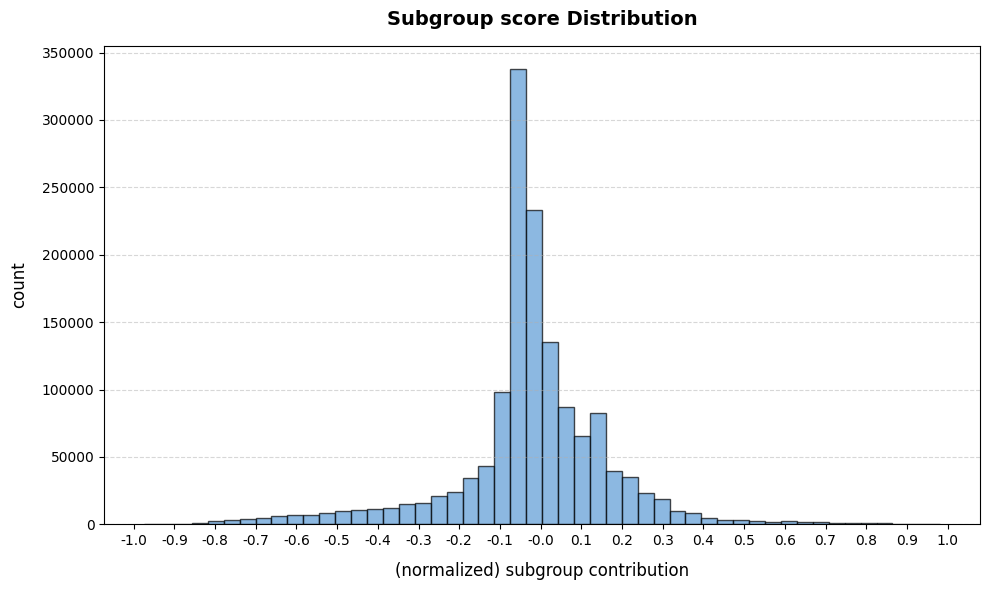

In [70]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. CSV 파일 로드
file_path = (
    "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/new_clipx_bli_normalized.csv"
)
df = pd.read_csv(file_path)

# 2. 시각화 설정 (그래프 크기 및 스타일)
plt.figure(figsize=(10, 6))

# 3. 히스토그램 그리기
# bins: 막대 개수 (데이터 양에 따라 30~50 적절), edgecolor: 막대 테두리 선
# alpha: 투명도, color: 막대 색상
plt.hist(
    df["normalized"],
    bins=50,
    color="#5B9BD5",
    edgecolor="#000000",
    alpha=0.7,
    # rwidth=0.85,
)
ticks = np.arange(-1.0, 1.01, 0.1)
plt.xticks(ticks, labels=[f"{x:.1f}" for x in ticks])

# 4. 그래프 요소 구성 (제목, 축 이름, 그리드)
plt.title("Subgroup score Distribution", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("(normalized) subgroup contribution", fontsize=12, labelpad=10)
plt.ylabel("count", fontsize=12, labelpad=10)

# 배경 격자선 추가 (가독성 향상)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# 5. 여백 최적화 및 출력/저장
plt.tight_layout()

# 그래프를 파일로 저장하고 싶다면 아래 주석을 해제하세요.
# plt.savefig('normalized_distribution.png', dpi=300)

plt.show()

🏆 [RANKING] Fragment Group by Average Attention Score:
1위 | carboxyl   | Mean Attn: 0.2533 (Data: 319개)
2위 | benzene    | Mean Attn: 0.0765 (Data: 17781개)
3위 | hydroxyl   | Mean Attn: 0.0648 (Data: 1278개)
4위 | halogen    | Mean Attn: 0.0097 (Data: 5207개)


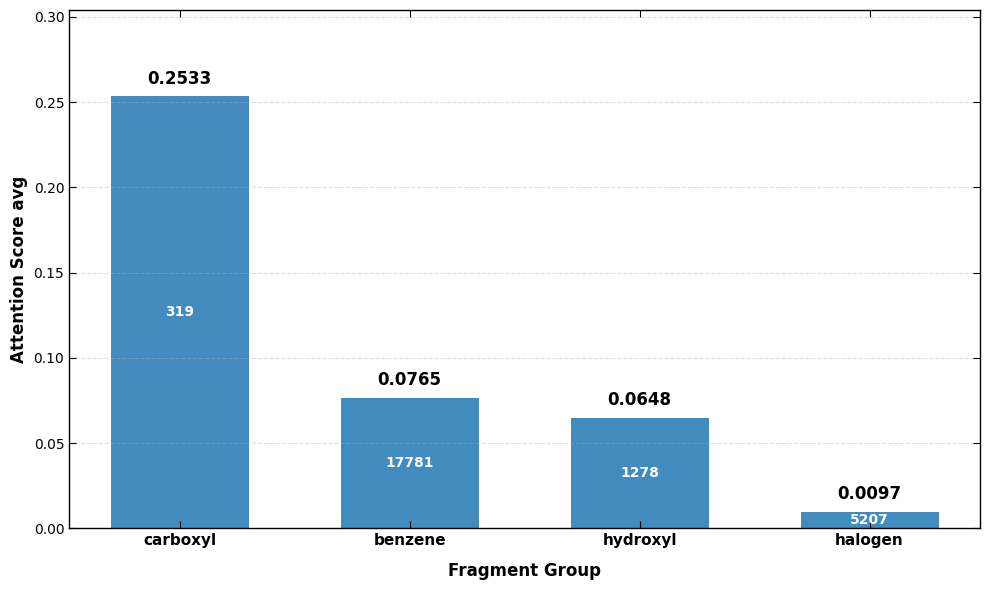

In [ ]:
import os
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 🚨 [폰트 경고 차단]
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# ---------------------------------------------------------------------------
# 1. 데이터 로드 및 정제
# ---------------------------------------------------------------------------
csv_file_path = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/C_paper_copy_analysis.csv"
# if not os.path.exists(csv_file_path):
#     csv_file_path = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/C_paper_copy_ana.csv"

if not os.path.exists(csv_file_path):
    csv_file_path = "C_paper_copy_analysis.csv" if os.path.exists("C_paper_copy_analysis.csv") else "C_paper_copy_ana.csv"

df = pd.read_csv(csv_file_path)

df.columns = df.columns.str.strip()
rename_dict = {col: 'frag_smiles' for col in df.columns if col.lower() == 'frag_smiles'}
if 'attn' in [c.lower() for c in df.columns]:
    for col in df.columns:
        if col.lower() == 'attn':
            rename_dict[col] = 'attn'
df = df.rename(columns=rename_dict)
df = df.dropna(subset=['attn', 'frag_smiles'])

# ---------------------------------------------------------------------------
# 2. 📂 정의된 fragment_dict 및 평균 연산
# ---------------------------------------------------------------------------
fragment_dict = {
    "benzene": ["c1ccccc1"],
    "hydroxyl": ["*O"],
    "carboxyl": ["*C(=O)O", "*C(=O)[O-]"],
    "halogen": ["*Br", "*F", "*Cl", "*I", "*CBr"]
}

# 각 그룹의 평균 attention score와 데이터 개수를 저장할 리스트
results = []

for group_name, smiles_list in fragment_dict.items():
    df_group = df[df['frag_smiles'].isin(smiles_list)]
    if len(df_group) > 0:
        mean_score = df_group['attn'].mean()
        count = len(df_group)
    else:
        mean_score = 0.0
        count = 0
        
    results.append({
        'Group': group_name,
        'Mean_Attn': mean_score,
        'Count': count
    })

# DataFrame으로 변환 후 Mean_Attn 기준으로 내림차순 정렬
df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by='Mean_Attn', ascending=False).reset_index(drop=True)

# 터미널에도 순위 출력
print("🏆 [RANKING] Fragment Group by Average Attention Score:")
print("="*60)
for idx, row in df_results.iterrows():
    print(f"{idx+1}위 | {row['Group']:<10} | Mean Attn: {row['Mean_Attn']:.4f} (Data: {row['Count']}개)")
print("="*60)

# ---------------------------------------------------------------------------
# 3. 📊 시각화 (Sorted Bar Chart)
# ---------------------------------------------------------------------------
plt.figure(figsize=(10, 6))

# # 색상을 순위별로 약간 다르게 지정하여 강조 (1위는 진하게, 나머지는 동일하게)
# colors = ['#1F4E79'] + ['#5B9BD5'] * (len(df_results) - 1)

bars = plt.bar(
    df_results['Group'], 
    df_results['Mean_Attn'], 
    # color=colors, 
    alpha=0.85, 
    width=0.6,
    edgecolor='none'
)

# 최대 Y값 기준으로 Y축 여유 공간 확보 (텍스트 겹침 방지)
max_y = df_results['Mean_Attn'].max()
plt.ylim(0, max_y * 1.2)

# 막대 상단에 수치 라벨 추가
for bar, count in zip(bars, df_results['Count']):
    height = bar.get_height()
    # 평균 수치 텍스트
    plt.text(
        bar.get_x() + bar.get_width() / 2, 
        height + (max_y * 0.02), 
        f'{height:.4f}', 
        ha='center', va='bottom', fontsize=12, fontweight='bold', color='black'
    )
    # 데이터 개수 텍스트
    plt.text(
        bar.get_x() + bar.get_width() / 2, 
        height / 2, 
        f'{count}', 
        ha='center', va='center', fontsize=10, color='white', fontweight='bold'
    )

# 축 및 타이틀 설정
# plt.title("Average Attention Score by Fragment Group", fontsize=15, fontweight='bold', pad=15)
plt.ylabel("Attention Score avg", fontsize=12, fontweight='bold')
plt.xlabel("Fragment Group", fontsize=12, fontweight='bold', labelpad=10)
plt.xticks(fontsize=11, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

# ---------------------------------------------------------------------------
# 4. 이미지 저장 / 출력
# ---------------------------------------------------------------------------
# output_img_name = "fragment_dict_mean_attn_sorted_bar.png"
# # shared_path 가 유효하면 해당 경로로 저장
# shared_path = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/"
# if os.path.exists(shared_path):
#     output_img_name = os.path.join(shared_path, output_img_name)

# plt.savefig(output_img_name, dpi=300, bbox_inches='tight')
# plt.show()

# print(f"🎉 성공: Attention Score 기준 정렬된 바 차트가 '{output_img_name}'로 저장되었습니다.")

=== bli_C_paper ('attn') 통계량 ===
count    77689.000000
mean        -0.000346
std          0.349195
min         -1.547150
25%         -0.129406
50%          0.015552
75%          0.140643
max          2.213990
Name: attn, dtype: float64

=== cli_C_paper ('attn') 통계량 ===
count    155378.000000
mean         -0.000627
std           0.196876
min          -1.334780
25%          -0.076547
50%           0.007513
75%           0.060482
max           2.299170
Name: attn, dtype: float64


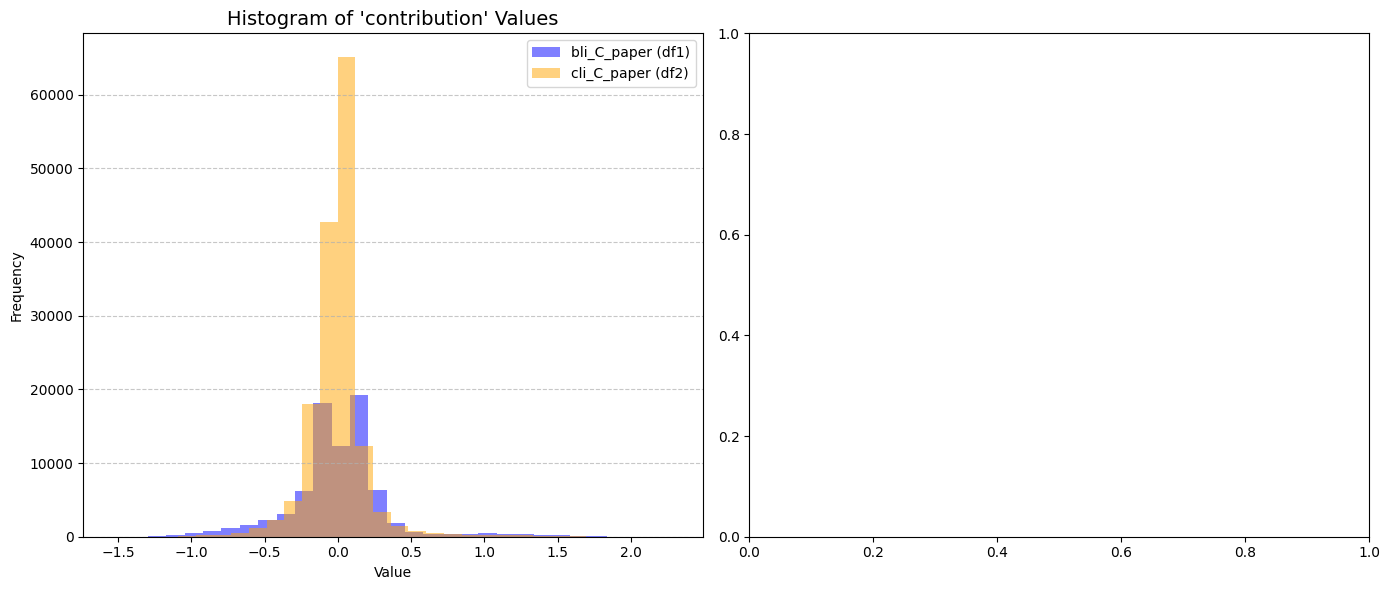

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 데이터 로드
df1 = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/bli_C_paper.csv")
df2 = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cli_C_paper.csv")

# 2. 요약 통계량 비교 출력 (텍스트로 수치 확인)
print("=== bli_C_paper ('attn') 통계량 ===")
print(df1['attn'].describe())
print("\n=== cli_C_paper ('attn') 통계량 ===")
print(df2['attn'].describe())

# 3. 시각화 영역 생성 (1행 2열 구조)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- [좌측 히스토그램]: 두 데이터의 분포 형태 비교 ---
# alpha로 투명도를 조절하여 겹치는 부분을 보기 쉽게 만듭니다.
axes[0].hist(df1['attn'], bins=30, alpha=0.5, label='bli_C_paper (df1)', color='blue')
axes[0].hist(df2['attn'], bins=30, alpha=0.5, label='cli_C_paper (df2)', color='orange')
axes[0].set_title("Histogram of 'contribution' Values", fontsize=14)
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# --- [우측 박스 플롯]: 중앙값, 사분위수 및 이상치 비교 ---
# # 두 데이터를 리스트로 묶어 한 번에 그립니다.
# axes[1].boxplot([df1['attn'].dropna(), df2['attn'].dropna()], labels=['bli_C_paper (df1)', 'cli_C_paper (df2)'])
# axes[1].set_title("Box Plot of 'contribution' Values", fontsize=14)
# axes[1].set_ylabel("Value")
# axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# 여백 조절 및 출력
plt.tight_layout()
plt.show()

## dist - frag

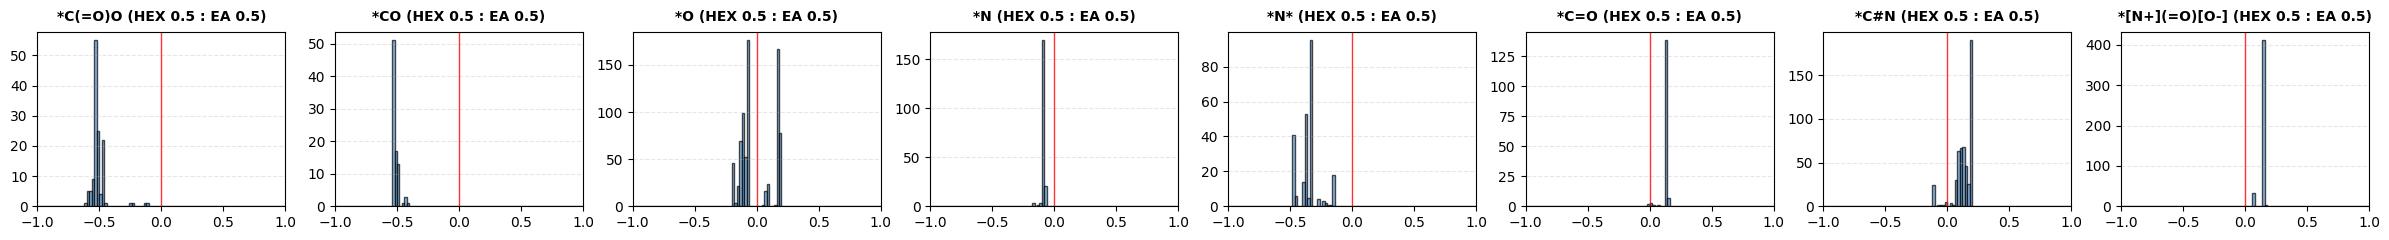

In [103]:

import math
import os
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 🚨 [폰트 경고 차단] Matplotlib 내부 폰트 경고 로그 원천 차단
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# ---------------------------------------------------------------------------
# 1. 데이터 로드 및 정제
# ---------------------------------------------------------------------------
df_cli = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_vol/hexea_BLI_final.csv")
# df_cli = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_vol/mcmeoh_BLI_final.csv")

# 컬럼명 앞뒤 공백 제거 및 유연한 맵핑 적용
df_cli.columns = df_cli.columns.str.strip()
rename_dict = {col: 'frag_smiles' for col in df_cli.columns if col.lower() == 'frag_smiles'}
if 'attn' in [c.lower() for c in df_cli.columns]:
    for col in df_cli.columns:
        if col.lower() == 'attn_norm':
            rename_dict[col] = 'attn_norm'
df_cli = df_cli.rename(columns=rename_dict)
df_cli = df_cli.dropna(subset=['attn_norm', 'frag_smiles'])


# ---------------------------------------------------------------------------
# 2. 이동상(Eluent) 조합별 데이터 분할 (조건 필터링)
# ---------------------------------------------------------------------------
# [조건 0] ratio1 = 0, ratio2 = 1 조건 필터링
df_cli = df_cli[(df_cli['ratio1'] == 0.5) & (df_cli['ratio2'] == 0.5)]

# 조건 1: Hexane (CCCCCC) + Ethyl Acetate (CCOC(C)=O)
cond1 = (df_cli['eluent1_smiles'] == 'CCCCCC') & (df_cli['eluent2_smiles'] == 'CCOC(C)=O')
df_env1 = df_cli[cond1]

# 조건 2: Chloroform (ClC(Cl)Cl) + Methanol (CO)
# cond2 = (df_cli['eluent1_smiles'] == 'ClCCl') & (df_cli['eluent2_smiles'] == 'CO')
# df_env2 = df_cli[cond2]

# ---------------------------------------------------------------------------
# 3. 정의된 fragment_dict 선언
# ---------------------------------------------------------------------------
fragment_dict = {
    # "*O": ["*O"],   # hydroxyl: Hbond donor
    # "*CO": ["*CO"],   # hydroxyl: Hbond donor
    # "*C(=O)O": ["*C(=O)O"],     # carboxyl : Hbond donor
    # "*N": ["*N"],       # amine : Hbond donor
    # "*N*": ["*N*"],      # amine : Hbond donor
    # "*[N+](=O)[O-]": ["*[N+](=O)[O-]"],  # nitro : 강한극성
    # "*C#N": ["*C#N"],  # cyano  : : Hbond acceptor
    # "*C=O": ["*C=O"],  # carbonyl : Hbond acceptor
    
    
    "*C(=O)O": ["*C(=O)O"],     # carboxyl : Hbond donor3
    "*CO": ["*CO"],   # hydroxyl: Hbond donor
    "*O": ["*O"],   # hydroxyl: Hbond donor
    "*N": ["*N"],       # amine : Hbond donor
    "*N*": ["*N*"],      # amine : Hbond donor
    "*C=O": ["*C=O"],  # carbonyl : Hbond acceptor
    "*C#N": ["*C#N"],  # cyano  : : Hbond acceptor
    "*[N+](=O)[O-]": ["*[N+](=O)[O-]"],  # nitro : 강한극성


    # "benzene": ["c1ccccc1"],
    # "*C": ["*C"],
    # "*CC" : ["*CC"],
    # "*CCC" : ["*CCC"],
    # "*C(C)(C)C": ["*C(C)(C)C"],
    # "*C(C)C": ["*C(C)C"],
    
}


# ---------------------------------------------------------------------------
# 4. 그래프 레이아웃 설정 (💡 변경: 행 2개 고정, 열: 작용기 개수만큼 가로 배치)
# ---------------------------------------------------------------------------
group_names = list(fragment_dict.keys())
nrows = 1               # 상단(EA/HEX) 1개 행 고정
ncols = len(group_names) * 1 # 작용기 개수만큼 열 생성

fig, axes = plt.subplots(
    nrows=nrows, 
    ncols=ncols,  
    figsize=(3.0 * ncols, 2.5), # 작용기 개수에 맞게 가로 크기 동적 조절 (3개 기준 가로 12인치)
    sharey=False  
)

# 1개의 작용기만 있을 때 axes가 1차원 배열이 되는 것을 방지하기 위한 예외 처리
if ncols == 1:
    axes = np.array([axes])

# ---------------------------------------------------------------------------
# 5. 각 작용기 및 Eluent 조합별 루프 돌며 시각화
# ---------------------------------------------------------------------------
num_groups = len(group_names)

for idx, group_name in enumerate(group_names):
    smiles_list = fragment_dict[group_name]

    # 각 Eluent 환경별로 해당 작용기 필터링
    df_g1 = df_env1[df_env1['frag_smiles'].isin(smiles_list)]
    # df_g2 = df_env2[df_env2['frag_smiles'].isin(smiles_list)]
    
    r1_g1 = df_g1['ratio1'].iloc[0] if not df_g1.empty else None
    r2_g1 = df_g1['ratio2'].iloc[0] if not df_g1.empty else None
    
    # r1_g2 = df_g2['ratio1'].iloc[0] if not df_g2.empty else None
    # r2_g2 = df_g2['ratio2'].iloc[0] if not df_g2.empty else None
    
    # 차트 작성을 위한 데이터 및 설정 매핑
    envs_data = [
        {"df": df_g1, "ax": axes[idx],              "title": f"{group_name} (HEX {r1_g1} : EA {r2_g1})", "color": "#5B9BD5"}
        # {"df": df_g2, "ax": axes[idx], "title": f"{group_name} (DCM {r1_g2} : MeOH {r2_g2})", "color": "#ED7D31"}
    ]

    for env in envs_data:
        ax = env["ax"]
        attn_vals = env["df"]['attn_norm']

        # 🎨 히스토그램 그리기
        ax.hist(
            attn_vals, 
            bins=100,
            range=(-1, 1),
            color=env["color"], 
            alpha=0.7, 
            edgecolor='black', 
            rwidth=1.0 # 폭에 대한 막대너비 비율 (구간너비 100%을 막대로 그림, 0%는 간격)
        )
        
        # 그래프 서식 설정
        ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
        ax.set_title(f"{env['title']}", fontsize=10, fontweight='bold', pad=8)
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        ax.set_xlim([-1, 1])
         
        # 🚨 0.0 지점에 빨간색 세로 선 그리기
        ax.axvline(x=0.0, color='red', linestyle='-', linewidth=1, alpha=0.8, zorder=2)

# 레이아웃 여백 최적화
plt.tight_layout()
plt.subplots_adjust(wspace=0.2, hspace=0.1)
# 그래프 출력 (또는 plt.savefig('result.png') 형태로 저장 가능)
plt.show()

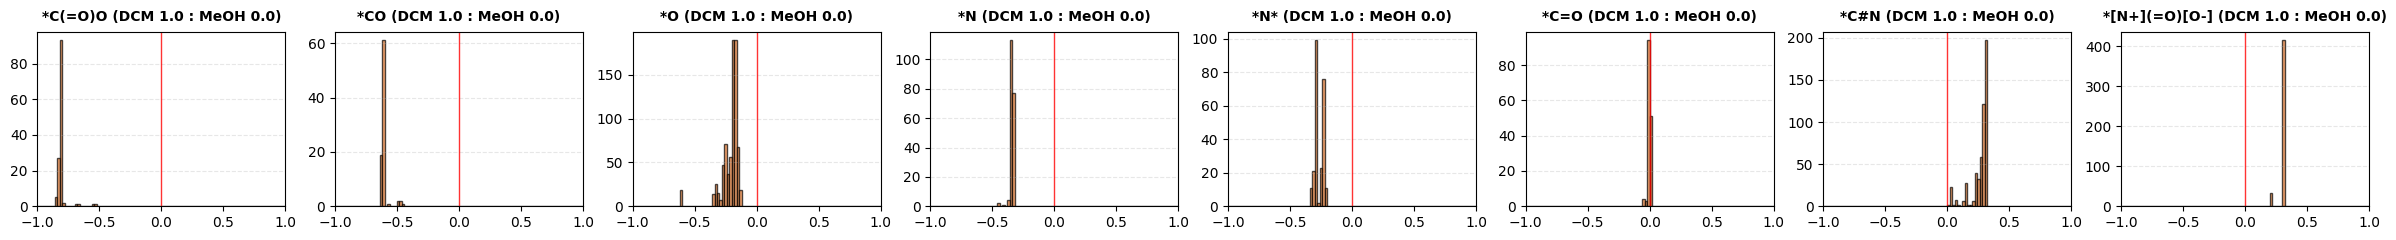

In [108]:

import math
import os
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 🚨 [폰트 경고 차단] Matplotlib 내부 폰트 경고 로그 원천 차단
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# ---------------------------------------------------------------------------
# 1. 데이터 로드 및 정제
# ---------------------------------------------------------------------------
# df_cli = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_vol/hexea_BLI_final.csv")
df_cli = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_vol/mcmeoh_BLI_final.csv")

# 컬럼명 앞뒤 공백 제거 및 유연한 맵핑 적용
df_cli.columns = df_cli.columns.str.strip()
rename_dict = {col: 'frag_smiles' for col in df_cli.columns if col.lower() == 'frag_smiles'}
if 'attn' in [c.lower() for c in df_cli.columns]:
    for col in df_cli.columns:
        if col.lower() == 'attn_norm':
            rename_dict[col] = 'attn_norm'
df_cli = df_cli.rename(columns=rename_dict)
df_cli = df_cli.dropna(subset=['attn_norm', 'frag_smiles'])


# ---------------------------------------------------------------------------
# 2. 이동상(Eluent) 조합별 데이터 분할 (조건 필터링)
# ---------------------------------------------------------------------------
# [조건 0] ratio1 = 0, ratio2 = 1 조건 필터링
df_cli = df_cli[(df_cli['ratio1'] == 1) & (df_cli['ratio2'] == 0)]

# 조건 1: Hexane (CCCCCC) + Ethyl Acetate (CCOC(C)=O)
# cond1 = (df_cli['eluent1_smiles'] == 'CCCCCC') & (df_cli['eluent2_smiles'] == 'CCOC(C)=O')
# df_env1 = df_cli[cond1]

# 조건 2: Chloroform (ClC(Cl)Cl) + Methanol (CO)
cond2 = (df_cli['eluent1_smiles'] == 'ClCCl') & (df_cli['eluent2_smiles'] == 'CO')
df_env2 = df_cli[cond2]

# ---------------------------------------------------------------------------
# 3. 정의된 fragment_dict 선언
# ---------------------------------------------------------------------------
fragment_dict = {

    # "*O": ["*O"],   # hydroxyl: Hbond donor
    # "*CO": ["*CO"],   # hydroxyl: Hbond donor
    # "*C(=O)O": ["*C(=O)O"],     # carboxyl : Hbond donor3
    # "*N": ["*N"],       # amine : Hbond donor
    # "*N*": ["*N*"],      # amine : Hbond donor
    # "*[N+](=O)[O-]": ["*[N+](=O)[O-]"],  # nitro : 강한극성
    # "*C#N": ["*C#N"],  # cyano  : : Hbond acceptor
    # "*C=O": ["*C=O"],  # carbonyl : Hbond acceptor
    
    
    
  
    "*C(=O)O": ["*C(=O)O"],     # carboxyl : Hbond donor3
    "*CO": ["*CO"],   # hydroxyl: Hbond donor
    "*O": ["*O"],   # hydroxyl: Hbond donor
    "*N": ["*N"],       # amine : Hbond donor
    "*N*": ["*N*"],      # amine : Hbond donor
    "*C=O": ["*C=O"],  # carbonyl : Hbond acceptor
    "*C#N": ["*C#N"],  # cyano  : : Hbond acceptor
    "*[N+](=O)[O-]": ["*[N+](=O)[O-]"],  # nitro : 강한극성


    # "benzene": ["c1ccccc1"],
    # "*C": ["*C"],
    # "*CC" : ["*CC"],
    # "*CCC" : ["*CCC"],
    # "*C(C)(C)C": ["*C(C)(C)C"],
    # "*C(C)C": ["*C(C)C"],
    
}


# ---------------------------------------------------------------------------
# 4. 그래프 레이아웃 설정 (💡 변경: 행 2개 고정, 열: 작용기 개수만큼 가로 배치)
# ---------------------------------------------------------------------------
group_names = list(fragment_dict.keys())
nrows = 1               # 상단(EA/HEX) 1개 행 고정
ncols = len(group_names) * 1 # 작용기 개수만큼 열 생성

fig, axes = plt.subplots(
    nrows=nrows, 
    ncols=ncols,  
    figsize=(3.0 * ncols, 2.5), # 작용기 개수에 맞게 가로 크기 동적 조절 (3개 기준 가로 12인치)
    sharey=False  
)

# 1개의 작용기만 있을 때 axes가 1차원 배열이 되는 것을 방지하기 위한 예외 처리
if ncols == 1:
    axes = np.array([axes])

# ---------------------------------------------------------------------------
# 5. 각 작용기 및 Eluent 조합별 루프 돌며 시각화
# ---------------------------------------------------------------------------
num_groups = len(group_names)

for idx, group_name in enumerate(group_names):
    smiles_list = fragment_dict[group_name]

    # 각 Eluent 환경별로 해당 작용기 필터링
    # df_g1 = df_env1[df_env1['frag_smiles'].isin(smiles_list)]
    df_g2 = df_env2[df_env2['frag_smiles'].isin(smiles_list)]
    
    # r1_g1 = df_g1['ratio1'].iloc[0] if not df_g1.empty else None
    # r2_g1 = df_g1['ratio2'].iloc[0] if not df_g1.empty else None
    
    r1_g2 = df_g2['ratio1'].iloc[0] if not df_g2.empty else None
    r2_g2 = df_g2['ratio2'].iloc[0] if not df_g2.empty else None
    
    # 차트 작성을 위한 데이터 및 설정 매핑
    envs_data = [
        # {"df": df_g1, "ax": axes[idx],              "title": f"{group_name} (HEX {r1_g1} : EA {r2_g1})", "color": "#5B9BD5"}
        {"df": df_g2, "ax": axes[idx], "title": f"{group_name} (DCM {r1_g2} : MeOH {r2_g2})", "color": "#ED7D31"}
    ]

    for env in envs_data:
        ax = env["ax"]
        attn_vals = env["df"]['attn_norm']

        # 🎨 히스토그램 그리기
        ax.hist(
            attn_vals, 
            bins=100,
            range=(-1, 1),
            color=env["color"], 
            alpha=0.7, 
            edgecolor='black', 
            rwidth=1.0 # 폭에 대한 막대너비 비율 (구간너비 100%을 막대로 그림, 0%는 간격)
        )
        
        # 그래프 서식 설정
        ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
        ax.set_title(f"{env['title']}", fontsize=10, fontweight='bold', pad=8)
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        ax.set_xlim([-1, 1])
         
        # 🚨 0.0 지점에 빨간색 세로 선 그리기
        ax.axvline(x=0.0, color='red', linestyle='-', linewidth=1, alpha=0.8, zorder=2)

# 레이아웃 여백 최적화
plt.tight_layout()
plt.subplots_adjust(wspace=0.2, hspace=0.1)
# 그래프 출력 (또는 plt.savefig('result.png') 형태로 저장 가능)
plt.show()

In [ ]:
########### 용매 조합 count ###########
import pandas as pd

# 1. CSV 파일 불러오기
df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/C_paper.csv')

# 2. 순서에 상관없이 동일한 조합으로 만들기 (정렬 후 튜플로 변환)
# 각 행(row)에서 eluent1과 eluent2를 꺼내 정렬한 뒤 tuple로 만듭니다.
df['eluent_pair'] = df.apply(
    lambda row: tuple(sorted([str(row['eluent1_smiles']), str(row['eluent2_smiles'])])), 
    axis=1
)

# 3. 조합별 빈도수 계산 (내림차순 자동 정렬)
pair_counts = df['eluent_pair'].value_counts()

# 4. 결과 출력
print("[용매 조합 count (내림차순)]")
for pair, count in pair_counts.items():
    print(f"조합: {pair} -> count {count}")

[용매 조합 count (내림차순)]
조합: ('CCCCCC', 'CCOC(C)=O') -> count 10831
조합: ('CO', 'ClCCl') -> count 1766
조합: ('CCCCCC', 'CCOCC') -> count 531
조합: ('CCCCC', 'CCOC(C)=O') -> count 325
조합: ('CCCCC', 'CCOCC') -> count 276
조합: ('C1CCCCC1', 'CCOC(C)=O') -> count 187
조합: ('CCCCCC', 'ClCCl') -> count 137
조합: ('CC(C)=O', 'CCCCCC') -> count 128
조합: ('CCCCCCC', 'CCOC(C)=O') -> count 114
조합: ('CCOC(C)=O', 'ClCCl') -> count 84
조합: ('CCOC(C)=O', 'CO') -> count 55
조합: ('CO', 'ClC(Cl)Cl') -> count 46
조합: ('CCOC(C)=O', 'Cc1ccccc1') -> count 43
조합: ('CCCCC', 'ClCCl') -> count 43
조합: ('CC(C)=O', 'ClCCl') -> count 30
조합: ('CCCCCC', 'COC(C)(C)C') -> count 30
조합: ('CC(C)=O', 'CCCCC') -> count 23
조합: ('CC#N', 'ClCCl') -> count 8
조합: ('CCN(CC)CC', 'CO') -> count 8
조합: ('CCO', 'ClCCl') -> count 7
조합: ('Cc1ccccc1', 'ClCCl') -> count 5
조합: ('CCOC(C)=O', 'c1ccccc1') -> count 4
조합: ('CCCCCC', 'COC(C)=O') -> count 3
조합: ('CO', 'ClCCOCCCl') -> count 3
조합: ('C1CCOC1', 'ClCCl') -> count 3
조합: ('CC#N', 'CCOC(C)=O') -> count 3

In [ ]:
# import pandas as pd

# # 1. CSV 파일 불러오기 (파일명을 본인의 환경에 맞게 수정하세요)
# df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/bli_C_paper.csv')

# # 2. 조건에 맞는 행 필터링하기
# # 조건 1: eluent1이 'CO'이고 eluent2가 'ClCCl'인 경우
# condition1 = (df['eluent1_smiles'] == 'CO') & (df['eluent2_smiles'] == 'ClCCl')

# # 조건 2: eluent1이 'ClCCl'이고 eluent2가 'CO'인 경우
# condition2 = (df['eluent1_smiles'] == 'ClCCl') & (df['eluent2_smiles'] == 'CO')

# # 두 조건 중 하나라도 만족(OR)하는 행 추출
# filtered_df = df[condition1 | condition2]

# # 3. 결과 확인 또는 저장
# print(filtered_df)

# # 필요한 경우 새 CSV 파일로 저장하려면 아래 주석을 해제하세요
# filtered_df.to_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/dcm/bli_Cpaper_dcm.csv', index=False)

                                                  Smiles eluent1_smiles eluent2_smiles    ratio1    ratio2  BLI_Rf  frag    frag_smiles                           atoms      attn
124    Brc1ccc2nc(-c3nc4ccc(Br)cn4c3NC3CCCCC3)c(NC3CC...          ClCCl             CO  0.953454  0.046546    0.18     0            *Br                             [0]  0.331115
125    Brc1ccc2nc(-c3nc4ccc(Br)cn4c3NC3CCCCC3)c(NC3CC...          ClCCl             CO  0.953454  0.046546    0.18     1            *Br                            [13]  0.331115
126    Brc1ccc2nc(-c3nc4ccc(Br)cn4c3NC3CCCCC3)c(NC3CC...          ClCCl             CO  0.953454  0.046546    0.18     2            *N*                            [17] -0.260424
127    Brc1ccc2nc(-c3nc4ccc(Br)cn4c3NC3CCCCC3)c(NC3CC...          ClCCl             CO  0.953454  0.046546    0.18     3            *N*                            [25] -0.260424
128    Brc1ccc2nc(-c3nc4ccc(Br)cn4c3NC3CCCCC3)c(NC3CC...          ClCCl             CO  0.953454  0.046546    

In [ ]:
# import pandas as pd

# # 1. CSV 파일 불러오기 (파일명을 본인의 환경에 맞게 수정하세요)
# df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cli_C_paper.csv')

# # 2. 조건에 맞는 행 필터링하기
# # 조건 1: eluent1이 'CO'이고 eluent2가 'ClCCl'인 경우
# condition1 = (df['eluent1_smiles'] == 'CO') & (df['eluent2_smiles'] == 'ClCCl')

# # 조건 2: eluent1이 'ClCCl'이고 eluent2가 'CO'인 경우
# condition2 = (df['eluent1_smiles'] == 'ClCCl') & (df['eluent2_smiles'] == 'CO')

# # 두 조건 중 하나라도 만족(OR)하는 행 추출
# filtered_df = df[condition1 | condition2]

# # 3. 결과 확인 또는 저장
# print(filtered_df)

# # 필요한 경우 새 CSV 파일로 저장하려면 아래 주석을 해제하세요
# filtered_df.to_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/dcm/cli_Cpaper_dcm.csv', index=False)

                                                   Smiles eluent1_smiles eluent2_smiles    ratio1    ratio2  CLI_Rf  frag    frag_smiles                           atoms      attn
248     Brc1ccc2nc(-c3nc4ccc(Br)cn4c3NC3CCCCC3)c(NC3CC...          ClCCl             CO  0.953454  0.046546    0.18     0            *Br                             [0]  0.186420
249     Brc1ccc2nc(-c3nc4ccc(Br)cn4c3NC3CCCCC3)c(NC3CC...          ClCCl             CO  0.953454  0.046546    0.18     1            *Br                            [13]  0.186420
250     Brc1ccc2nc(-c3nc4ccc(Br)cn4c3NC3CCCCC3)c(NC3CC...          ClCCl             CO  0.953454  0.046546    0.18     2            *N*                            [17] -0.146089
251     Brc1ccc2nc(-c3nc4ccc(Br)cn4c3NC3CCCCC3)c(NC3CC...          ClCCl             CO  0.953454  0.046546    0.18     3            *N*                            [25] -0.146089
252     Brc1ccc2nc(-c3nc4ccc(Br)cn4c3NC3CCCCC3)c(NC3CC...          ClCCl             CO  0.953454  0.0465

## 분자 1개 개별분석

In [ ]:
########## BLI 그림, 분자 1개 개별확인 ##########

score = visualize_segment_attention2(
    BLI_segment,
    "OC1=CC=CC=C1C=O",
    "OC1=CC(C=O)=CC=C1",
    "C1=CC(=CC=C1C=O)O",
    "CCCCCC",
    "CCOC(C)=O",
    0.0,
    1.0,
    ratio=True,
)

Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].


frag,frag_smiles,atoms,subgroup_contributions,normalized
0,*C=O,"[0, 1]",-0.0499574,-0.049916
1,*O,[6],0.0140269,0.014026
2,c1ccccc1,"[2, 3, 4, 5, 7, 8]",1.03716,0.776765


In [ ]:
## 분자 1개 대해 svg 파일 저장
 
import os
import re
from IPython.utils import capture

# 1. IPython 출력 캡처 기능을 사용해 함수 실행 도중 화면에 출력되는 HTML을 가로챕니다.
with capture.capture_output() as cap:
    score = visualize_segment_attention2(
        BLI_segment,
        "CC(=O)NC1=CC=CC=C1",
        "CCCCCC",
        "O=C(OCC)C",
        0.3,
        0.7,
        ratio=True,
    )

# 2. 가로챈 출력 결과를 주피터 화면에 다시 정상적으로 뿌려줍니다.
# cap.show()

# 3. 캡처된 출력 데이터에서 SVG 태그(<svg ... </svg>) 부분을 찾아서 파일로 저장합니다.
captured_html = "".join([output.data.get('text/html', '') for output in cap.outputs if 'text/html' in output.data])

# 정규식을 사용해 HTML 안에 포함된 SVG 코드만 추출합니다.
svg_matches = re.findall(r'(<svg.*?</svg>)', captured_html, re.DOTALL)

# if svg_matches:
#     # 📂 img 폴더가 없으면 자동으로 생성합니다.
#     output_dir = "img"
#     os.makedirs(output_dir, exist_ok=True)
    
#     for i, svg_code in enumerate(svg_matches):
#         # 파일명을 결정합니다.
#         file_name = f"b_cli_7_{i}.svg" if len(svg_matches) > 1 else "b_bli_7.svg"
        
#         # 📂 img 폴더 경로와 파일명을 안전하게 결합합니다. (예: img/a_bli.svg)
#         file_path = os.path.join(output_dir, file_name)
        
#         with open(file_path, "w", encoding="utf-8") as f:
#             f.write(svg_code)
#         print(f"🎉 성공: 고화질 SVG 이미지가 '{file_path}'에 저장되었습니다!")
# else:
#     print("⚠️ 출력 데이터에서 SVG 이미지를 찾지 못했습니다.")

In [ ]:
########## CLI 그림, 분자 1개 개별확인 ##########

score = visualize_segment_attention2(
    CLI_segment,
    "CC(C)(C)C1=CC=C(C=O)C=C1",
    "CCCCCC",
    "CCOC(C)=O",
    # 1,0                   # 1:0
    # 0.7498,0.2502         # 4:1
    # 0.7893,0.2107 # 10:1
    # 0.4283, 0.5717        # 1:1
    0.5, 0.5
    ,ratio=True,
)
# ele1:HEX, ele2:EA

Positional arguments are provided. Note that arguments should be in the order of ['Smiles', 'eluent1_smiles', 'eluent2_smiles'] and ['ratio1', 'ratio2'].


frag,frag_smiles,atoms,ratio_weighted_contribution1,normalized
0,*C=O,"[9, 8]",-0.124978,-0.124331
1,*C(C)(C)C,"[0, 2, 3, 1]",0.110953,0.110500
2,c1ccccc1,"[4, 5, 6, 7, 10, 11]",0.239769,0.235277
frag,frag_smiles,atoms,ratio_weighted_contribution2,normalized
0,*C=O,"[9, 8]",0.380211,0.362890
1,*C(C)(C)C,"[0, 2, 3, 1]",0.321238,0.310626
2,c1ccccc1,"[4, 5, 6, 7, 10, 11]",1.24588,0.847124


In [13]:
########## target molecule 1개에 대해, EA 5%씩 증가시키며 BLI_Rf 예측 ##########

import numpy as np
import pandas as pd

# ==========================================
# 1. Smiles 설정 (이 부분만 수정하시면 됩니다!)
# ==========================================
TARGET_SMILES = "OCC1=CC=C(C=C1)N(=O)=O"

# 용매 및 고정값 설정 (필요시 변경 가능)
ELUENT1 = "CCCCCC"      # HEX
ELUENT2 = "CCOC(C)=O"   # EA
# ELUENT1 = "CO"      # MeOH
# ELUENT2 = "ClC(Cl)"   # DCM

# ==========================================
# 2. 21개 ratio 조합 자동 생성 (1.0~0.0 / 0.0~1.0)
# ==========================================
# 1.0부터 0.0까지 0.05 간격으로 총 21개 생성 (round 처리로 부동소수점 오차 방지)
ratios1 = [round(x, 2) for x in np.linspace(1.0, 0.0, 21)]
ratios2 = [round(1.0 - x, 2) for x in ratios1]

# 데이터 개수가 11개에서 21개로 늘어났으므로 곱하는 상수를 21로 변경 
total_rows = len(ratios1)  # 21

# DataFrame 데이터 빌드
data = {
    "Smiles": [TARGET_SMILES] * total_rows,
    "eluent1_smiles": [ELUENT1] * total_rows,
    "eluent2_smiles": [ELUENT2] * total_rows,
    "ratio1": ratios1,
    "ratio2": ratios2,
    # 기존 컬럼 구조 유지를 위한 빈 값 설정
    "Rf": [None] * total_rows,
    "Rf_type": [None] * total_rows,
    "DataSource": [None] * total_rows,
    "doi": [None] * total_rows,
    "sample_id": [None] * total_rows,
}
df_custom = pd.DataFrame(data)


# ==========================================
# 3. 예측 함수 및 실행 (기존 로직 유지)
# ==========================================
def predict_many(analyzer, df, prefix):
    columns = analyzer.molecule_columns + analyzer.numeric_input_columns
    predictions = analyzer.predict(
        **{column: df[column].tolist() for column in columns}
    )

    rf_values = []
    for _, row in df.iterrows():
        key = tuple(row[column] for column in columns)
        rf_values.append(float(np.asarray(predictions[key]).reshape(-1)[0]))

    return pd.DataFrame({f"{prefix}_Rf": rf_values}, index=df.index)


# 예측 수행 (BLI_segment 객체가 사전에 선언되어 있어야 합니다)
predict = predict_many(BLI_segment, df_custom, "BLI")

# 결과 병합
result_df_BLI = pd.concat([df_custom, predict], axis=1)

# Rf값 클리핑 (0 미만: 0, 1 초과: 1)
result_df_BLI["BLI_Rf"] = result_df_BLI["BLI_Rf"].clip(lower=0, upper=1)

# ==========================================
# 4. 주피터 노트북에 결과 바로 출력
# ==========================================
result_df_BLI
# ele1:HEX, ele2:EA

Generating eluent2_smiles graphs: 100%|██████████| 21/21 [00:00<00:00, 169.99it/s]


,Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi,sample_id,BLI_Rf
0,OCC1=CC=C(C=C1)N(=O)=O,CCCCCC,CCOC(C)=O,1.00,0.00,None,None,None,None,None,0.000000
1,OCC1=CC=C(C=C1)N(=O)=O,CCCCCC,CCOC(C)=O,0.95,0.05,None,None,None,None,None,0.002759
2,OCC1=CC=C(C=C1)N(=O)=O,CCCCCC,CCOC(C)=O,0.90,0.10,None,None,None,None,None,0.025833
3,OCC1=CC=C(C=C1)N(=O)=O,CCCCCC,CCOC(C)=O,0.85,0.15,None,None,None,None,None,0.052027
4,OCC1=CC=C(C=C1)N(=O)=O,CCCCCC,CCOC(C)=O,0.80,0.20,None,None,None,None,None,0.075199
5,OCC1=CC=C(C=C1)N(=O)=O,CCCCCC,CCOC(C)=O,0.75,0.25,None,None,None,None,None,0.112852
6,OCC1=CC=C(C=C1)N(=O)=O,CCCCCC,CCOC(C)=O,0.70,0.30,None,None,None,None,None,0.157803
7,OCC1=CC=C(C=C1)N(=O)=O,CCCCCC,CCOC(C)=O,0.65,0.35,None,None,None,None,None,0.209546
8,OCC1=CC=C(C=C1)N(=O)=O,CCCCCC,CCOC(C)=O,0.60,0.40,None,None,None,None,None,0.287235
9,OCC1=CC=C(C=C1)N(=O)=O,CCCCCC,CCOC(C)=O,0.55,0.45,None,None,None,None,None,0.373403


In [ ]:
########## target molecule 1개에 대해, EA 5%씩 증가시키며 CLI_Rf 예측 ##########

######

import numpy as np
import pandas as pd

# ==========================================
# 1. Smiles 설정 (이 부분만 수정하시면 됩니다!)
# ==========================================
TARGET_SMILES = "OCC1=CC=CC=C1"

ELUENT1 = "CCCCCC"      # HEX
ELUENT2 = "CCOC(C)=O"   # EA
# ELUENT1 = "CO"      # MeOH
# ELUENT2 = "ClC(Cl)"   # DCM

# ==========================================
# 2. 21개 ratio 조합 자동 생성 (1.0~0.0 / 0.0~1.0)
# ==========================================
# 1.0부터 0.0까지 0.05 간격으로 총 21개 생성 (round 처리로 부동소수점 오차 방지)
ratios1 = [round(x, 2) for x in np.linspace(1.0, 0.0, 21)]
ratios2 = [round(1.0 - x, 2) for x in ratios1]

# 데이터 개수가 11개에서 21개로 늘어났으므로 곱하는 상수를 21로 변경 
total_rows = len(ratios1)  # 21

# DataFrame 데이터 빌드
data = {
    "Smiles": [TARGET_SMILES] * total_rows,
    "eluent1_smiles": [ELUENT1] * total_rows,
    "eluent2_smiles": [ELUENT2] * total_rows,
    "ratio1": ratios1,
    "ratio2": ratios2,
    # 기존 컬럼 구조 유지를 위한 빈 값 설정
    "Rf": [None] * total_rows,
    "Rf_type": [None] * total_rows,
    "DataSource": [None] * total_rows,
    "doi": [None] * total_rows,
    "sample_id": [None] * total_rows,
}
df_custom = pd.DataFrame(data)


# ==========================================
# 3. 예측 함수 및 실행 (기존 로직 유지)
# ==========================================
def predict_many(analyzer, df, prefix):
    columns = analyzer.molecule_columns + analyzer.numeric_input_columns
    predictions = analyzer.predict(
        **{column: df[column].tolist() for column in columns}
    )

    rf_values = []
    for _, row in df.iterrows():
        key = tuple(row[column] for column in columns)
        rf_values.append(float(np.asarray(predictions[key]).reshape(-1)[0]))

    return pd.DataFrame({f"{prefix}_Rf": rf_values}, index=df.index)


# 예측 수행 (CLI_segment 객체가 사전에 선언되어 있어야 합니다)
predict = predict_many(CLI_segment, df_custom, "CLI")

# 결과 병합
result_df_CLI = pd.concat([df_custom, predict], axis=1)

# Rf값 클리핑 (0 미만: 0, 1 초과: 1)
result_df_CLI["CLI_Rf"] = result_df_CLI["CLI_Rf"].clip(lower=0, upper=1)

# ==========================================
# 4. 주피터 노트북에 결과 바로 출력
# ==========================================
result_df_CLI
# ele1:HEX, ele2:EA

NameError: name 'CLI_segment' is not defined

## dataset 생성

In [ ]:
### csv파일 Rf값 예측, BLI (result_df_BLI) ###
# 계산예측셀
import pandas as pd

# CSV 파일에는 Smiles, eluent1_smiles, eluent2_smiles, ratio1, ratio2 컬럼이 있어야 합니다.
df_BLI = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/ex/ex.csv")


def predict_many(analyzer, df, prefix):
    columns = analyzer.molecule_columns + analyzer.numeric_input_columns
    predictions = analyzer.predict(**{column: df[column].tolist() for column in columns})

    rf_values = []
    for _, row in df.iterrows():
        key = tuple(row[column] for column in columns)
        rf_values.append(float(np.asarray(predictions[key]).reshape(-1)[0]))

    return pd.DataFrame({f"{prefix}_Rf": rf_values}, index=df.index)

predict = predict_many(BLI_segment, df_BLI, "BLI")

result_df_BLI = pd.concat(
    [
        df_BLI,predict
    ],
    axis=1,
)

# result_df_BLI
# CSV 파일로 저장하기 (index=False를 주면 맨 앞의 행 번호(인덱스)를 제외하고 저장합니다)
result_df_BLI.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/ex/ex_bli.csv", index=False)

# result_df Rf값 클리핑
# 기존 result_df의 BLI_Rf 컬럼 클리핑 (0 미만: 0, 1 초과: 1)
result_df_BLI['BLI_Rf'] = result_df_BLI['BLI_Rf'].clip(lower=0, upper=1)

# 클리핑된 데이터를 다른 이름으로 저장
result_df_BLI.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/ex/ex_bli_clip.csv", index=False)

In [ ]:
########## sum_contribution BLI ##########
# 계산예측셀
import os
import re
import pandas as pd
from bs4 import BeautifulSoup
from IPython.utils import capture
import traceback

# ---------------------------------------------------------------------------
# 1. 경로 설정 및 기준 데이터 로드
# ---------------------------------------------------------------------------
reference_csv_path = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/C_paper_copy.csv"
output_csv_path = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/analysis_C_paper.csv"

if not os.path.exists(reference_csv_path):
    raise FileNotFoundError(f"'{reference_csv_path}' 파일을 찾을 수 없습니다. 경로를 확인해주세요.")

# 원본 CSV 로드
df_ref = pd.read_csv(reference_csv_path)

# 💡 문자열 공백 정제 및 부동소수점 매칭률 확보를 위해 자릿수를 고정합니다.
df_ref['Smiles'] = df_ref['Smiles'].str.strip()
df_ref['eluent1_smiles'] = df_ref['eluent1_smiles'].str.strip()
df_ref['eluent2_smiles'] = df_ref['eluent2_smiles'].str.strip()
df_ref['ratio1'] = df_ref['ratio1'].astype(float).round(6)
df_ref['ratio2'] = df_ref['ratio2'].astype(float).round(6)

# 조인 시 N:N 매칭 분출을 막기 위해 고유 조건 세트만 먼저 추출합니다.
unique_conditions = df_ref[['Smiles', 'eluent1_smiles', 'eluent2_smiles', 'ratio1', 'ratio2', 'BLI_Rf']].drop_duplicates().reset_index(drop=True)

print(f"🚀 총 {len(unique_conditions)}개의 조합에 대해 HTML 캡처 및 테이블 데이터 수집을 시작합니다...")

# 기존 파일 초기화
if os.path.exists(output_csv_path):
    os.remove(output_csv_path)

all_table_data = []
success_count = 0
error_count = 0

# ---------------------------------------------------------------------------
# 2. 14,711개 고유 조건 루프 순회 실행
# ---------------------------------------------------------------------------
for idx_cond, row_cond in unique_conditions.iterrows():
    
    smiles = row_cond['Smiles']
    eluent1_smiles = row_cond['eluent1_smiles']
    eluent2_smiles = row_cond['eluent2_smiles']
    ratio1 = row_cond['ratio1']
    ratio2 = row_cond['ratio2']
    bli_rf = row_cond['BLI_Rf']
    
    # 1️⃣ IPython 출력 캡처 기능을 사용해 함수 실행 도중 화면에 출력되는 HTML을 가로챕니다.
    with capture.capture_output() as cap:
        try:
            score = visualize_segment_attention2(
                BLI_segment,
                smiles,
                eluent1_smiles,
                eluent2_smiles,
                ratio1,
                ratio2,
                ratio=True,
            )
        except Exception as e:
            error_count += 1
            if error_count <= 3:
                print(f"\n❌ [함수 에러] Smiles: {smiles} (비율 {ratio1}:{ratio2})")
                traceback.print_exc()
            continue
            
    # 2️⃣ 가로챈 출력 결과를 주피터 화면에 다시 정상적으로 뿌려줍니다.
    # cap.show()
    
    # 3️⃣ 캡처된 출력 데이터에서 HTML 추출 후 표(Table) 파싱
    captured_html = "".join([output.data.get('text/html', '') for output in cap.outputs if 'text/html' in output.data])
    
    soup = BeautifulSoup(captured_html, 'html.parser')
    panels = soup.find_all('div', style=lambda value: value and 'display:inline-block' in value)
    
    if not panels:
        panels = [soup]
        
    found_table_in_loop = False
    for panel in panels:
        table = panel.find('table')
        if not table:
            continue
            
        rows = table.find_all('tr')
        for row in rows:
            cols = row.find_all(['td', 'th'])
            cols_text = [c.get_text().strip() for c in cols]
            
            # 헤더 행 및 규격에 맞지 않는 행 제외
            if not cols_text or cols_text[0] == 'frag' or len(cols_text) < 4:
                continue
            
            frag = cols_text[0]
            frag_smiles = cols_text[1]
            atoms = cols_text[2]
            attn = float(cols_text[3])
            
            # 📌 요청하신 10개 컬럼 레이아웃 순서대로 정확히 적재
            all_table_data.append({
                "Smiles": smiles,
                "eluent1_smiles": eluent1_smiles,
                "eluent2_smiles": eluent2_smiles,
                "ratio1": round(float(ratio1), 6),
                "ratio2": round(float(ratio2), 6),
                "BLI_Rf": bli_rf,
                "frag": frag,
                "frag_smiles": frag_smiles,
                "atoms": atoms,
                "attn": attn
            })
            found_table_in_loop = True

    if found_table_in_loop:
        success_count += 1

    # 💾 대용량 보관 가동: 500개 조합 단위로 끊어서 CSV 파일에 누적(Append)하여 메모리 리셋
    if (idx_cond + 1) % 500 == 0 and all_table_data:
        df_chunk = pd.DataFrame(all_table_data)
        
        if not os.path.exists(output_csv_path):
            df_chunk.to_csv(output_csv_path, index=False, encoding="utf-8-sig")
        else:
            df_chunk.to_csv(output_csv_path, mode='a', header=False, index=False, encoding="utf-8-sig")
            
        all_table_data = []  # 메모리 비우기
        print(f"🔄 중간 적재 완료: {idx_cond + 1}/{len(unique_conditions)} 진행 중... (성공: {success_count}건, 스킵: {error_count}건)")

# ---------------------------------------------------------------------------
# 3. 잔여 데이터 최종 정산
# ---------------------------------------------------------------------------
if all_table_data:
    df_chunk = pd.DataFrame(all_table_data)
    if not os.path.exists(output_csv_path):
        df_chunk.to_csv(output_csv_path, index=False, encoding="utf-8-sig")
    else:
        df_chunk.to_csv(output_csv_path, mode='a', header=False, index=False, encoding="utf-8-sig")

print("\n" + "="*60)
print(f"🏁 데이터 수집 및 CSV 빌드 프로세스 종료!")
if os.path.exists(output_csv_path):
    print(f"💾 마스터 파일이 안전하게 보관되었습니다: '{output_csv_path}'")
    print(f"📊 최종 파일 총 데이터 행 수: {len(pd.read_csv(output_csv_path))} 행")
else:
    print("❌ 실패: 표 파싱에 실패하여 파일이 생성되지 않았습니다.")
print("="*60)

🚀 총 14711개의 조합에 대해 HTML 캡처 및 테이블 데이터 수집을 시작합니다...
🔄 중간 적재 완료: 500/14711 진행 중... (성공: 500건, 스킵: 0건)
🔄 중간 적재 완료: 1000/14711 진행 중... (성공: 1000건, 스킵: 0건)
🔄 중간 적재 완료: 1500/14711 진행 중... (성공: 1500건, 스킵: 0건)
🔄 중간 적재 완료: 2000/14711 진행 중... (성공: 2000건, 스킵: 0건)
🔄 중간 적재 완료: 2500/14711 진행 중... (성공: 2500건, 스킵: 0건)
🔄 중간 적재 완료: 3000/14711 진행 중... (성공: 2999건, 스킵: 1건)
🔄 중간 적재 완료: 3500/14711 진행 중... (성공: 3499건, 스킵: 1건)
🔄 중간 적재 완료: 4000/14711 진행 중... (성공: 3999건, 스킵: 1건)
🔄 중간 적재 완료: 4500/14711 진행 중... (성공: 4495건, 스킵: 5건)
🔄 중간 적재 완료: 5000/14711 진행 중... (성공: 4995건, 스킵: 5건)
🔄 중간 적재 완료: 5500/14711 진행 중... (성공: 5495건, 스킵: 5건)
🔄 중간 적재 완료: 6000/14711 진행 중... (성공: 5995건, 스킵: 5건)
🔄 중간 적재 완료: 6500/14711 진행 중... (성공: 6495건, 스킵: 5건)
🔄 중간 적재 완료: 7000/14711 진행 중... (성공: 6995건, 스킵: 5건)
🔄 중간 적재 완료: 7500/14711 진행 중... (성공: 7495건, 스킵: 5건)
🔄 중간 적재 완료: 8000/14711 진행 중... (성공: 7995건, 스킵: 5건)
🔄 중간 적재 완료: 8500/14711 진행 중... (성공: 8495건, 스킵: 5건)
🔄 중간 적재 완료: 9000/14711 진행 중... (성공: 8995건, 스킵: 5건)
🔄 중간 적재 완료: 9500/14711 진행 중... (성공

In [ ]:
import pandas as pd
# 계산예측셀
# 모하는셀인지모르갯음
# CSV 파일에는 Smiles, eluent1_smiles, eluent2_smiles, ratio1, ratio2 컬럼이 있어야 합니다.
df_example = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/ex.csv")


def predict_many(analyzer, df, prefix):
    columns = analyzer.molecule_columns + analyzer.numeric_input_columns
    predictions = analyzer.predict(**{column: df[column].tolist() for column in columns})

    rf_values = []
    for _, row in df.iterrows():
        key = tuple(row[column] for column in columns)
        rf_values.append(float(np.asarray(predictions[key]).reshape(-1)[0]))

    return pd.DataFrame({f"{prefix}_Rf": rf_values}, index=df.index)

predict = predict_many(BLI_segment, df_example, "BLI")

# result_df = pd.concat(
#     [
#         df_example,
#         predict_many(CLI_segment, df_example, "CLI"),
#         predict_many(BLI_segment, df_example, "BLI"),
#     ],
#     axis=1,
# )

predict

Generating Smiles graphs:   0%|          | 673/243540 [00:05<31:36, 128.04it/s]


KeyboardInterrupt: 

In [ ]:
### csv파일 Rf값 예측, BLI (result_df_BLI) ### 최종
# 계산예측셀
import pandas as pd

# CSV 파일에는 Smiles, eluent1_smiles, eluent2_smiles, ratio1, ratio2 컬럼이 있어야 합니다.
df_BLI = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/ex/ex.csv")


def predict_many(analyzer, df, prefix):
    columns = analyzer.molecule_columns + analyzer.numeric_input_columns
    predictions = analyzer.predict(**{column: df[column].tolist() for column in columns})

    rf_values = []
    for _, row in df.iterrows():
        key = tuple(row[column] for column in columns)
        rf_values.append(float(np.asarray(predictions[key]).reshape(-1)[0]))

    return pd.DataFrame({f"{prefix}_Rf": rf_values}, index=df.index)

predict = predict_many(BLI_segment, df_BLI, "BLI")

result_df_BLI = pd.concat(
    [
        df_BLI,predict
    ],
    axis=1,
)

# result_df_BLI
# CSV 파일로 저장하기 (index=False를 주면 맨 앞의 행 번호(인덱스)를 제외하고 저장합니다)
result_df_BLI.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/ex/ex_bli.csv", index=False)

# result_df Rf값 클리핑
# 기존 result_df의 BLI_Rf 컬럼 클리핑 (0 미만: 0, 1 초과: 1)
result_df_BLI['BLI_Rf'] = result_df_BLI['BLI_Rf'].clip(lower=0, upper=1)

# 클리핑된 데이터를 다른 이름으로 저장
result_df_BLI.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/ex/ex_bli_clip.csv", index=False)

In [74]:
print(df_bli['attn'].min(), df_bli['attn'].max())

-1.54715 2.21399


In [ ]:

########## sum_contribution CLI ##########
# 여기2: CLI
# 계산예측셀 CLI

import os
import re
import pandas as pd
from bs4 import BeautifulSoup
from IPython.utils import capture
import traceback

# ---------------------------------------------------------------------------
# 1. 경로 설정 및 기준 데이터 로드
# ---------------------------------------------------------------------------
reference_csv_path = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/C_paper_copy.csv"
output_csv_path = "/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cli_C_paper.csv"

if not os.path.exists(reference_csv_path):
    raise FileNotFoundError(f"'{reference_csv_path}' 파일을 찾을 수 없습니다. 경로를 확인해주세요.")

# 원본 CSV 로드
df_ref = pd.read_csv(reference_csv_path)

# 💡 문자열 공백 정제 및 부동소수점 매칭률 확보를 위해 자릿수를 고정합니다.
df_ref['Smiles'] = df_ref['Smiles'].str.strip()
df_ref['eluent1_smiles'] = df_ref['eluent1_smiles'].str.strip()
df_ref['eluent2_smiles'] = df_ref['eluent2_smiles'].str.strip()
df_ref['ratio1'] = df_ref['ratio1'].astype(float).round(6)
df_ref['ratio2'] = df_ref['ratio2'].astype(float).round(6)

# 조인 시 N:N 매칭 분출을 막기 위해 고유 조건 세트만 먼저 추출합니다.
unique_conditions = df_ref[['Smiles', 'eluent1_smiles', 'eluent2_smiles', 'ratio1', 'ratio2', 'CLI_Rf']].drop_duplicates().reset_index(drop=True)

print(f"🚀 총 {len(unique_conditions)}개의 조합에 대해 HTML 캡처 및 테이블 데이터 수집을 시작합니다...")

# 기존 파일 초기화
if os.path.exists(output_csv_path):
    os.remove(output_csv_path)

all_table_data = []
success_count = 0
error_count = 0

# ---------------------------------------------------------------------------
# 2. 14,711개 고유 조건 루프 순회 실행
# ---------------------------------------------------------------------------
for idx_cond, row_cond in unique_conditions.iterrows():
    smiles = row_cond['Smiles']
    eluent1_smiles = row_cond['eluent1_smiles']
    eluent2_smiles = row_cond['eluent2_smiles']
    ratio1 = row_cond['ratio1']
    ratio2 = row_cond['ratio2']
    cli_rf = row_cond['CLI_Rf']
    
    # 1️⃣ IPython 출력 캡처 기능을 사용해 함수 실행 도중 화면에 출력되는 HTML을 가로챕니다.
    with capture.capture_output() as cap:
        try:
            score = visualize_segment_attention2(
                CLI_segment,
                smiles,
                eluent1_smiles,
                eluent2_smiles,
                ratio1,
                ratio2,
                ratio=True,
            )
        except Exception as e:
            error_count += 1
            if error_count <= 3:
                print(f"\n❌ [함수 에러] Smiles: {smiles} (비율 {ratio1}:{ratio2})")
                traceback.print_exc()
            continue
            
    # 2️⃣ 가로챈 출력 결과를 주피터 화면에 다시 정상적으로 뿌려줍니다.
    # cap.show()
    
    # 3️⃣ 캡처된 출력 데이터에서 HTML 추출 후 표(Table) 파싱
    captured_html = "".join([output.data.get('text/html', '') for output in cap.outputs if 'text/html' in output.data])
    
    soup = BeautifulSoup(captured_html, 'html.parser')
    panels = soup.find_all('div', style=lambda value: value and 'display:inline-block' in value)
    
    if not panels:
        panels = [soup]
        
    found_table_in_loop = False
    for panel in panels:
        table = panel.find('table')
        if not table:
            continue
            
        rows = table.find_all('tr')
        for row in rows:
            cols = row.find_all(['td', 'th'])
            cols_text = [c.get_text().strip() for c in cols]
            
            # 헤더 행 및 규격에 맞지 않는 행 제외
            if not cols_text or cols_text[0] == 'frag' or len(cols_text) < 4:
                continue
            
            frag = cols_text[0]
            frag_smiles = cols_text[1]
            atoms = cols_text[2]
            attn = float(cols_text[3])
            
            # 📌 요청하신 10개 컬럼 레이아웃 순서대로 정확히 적재
            all_table_data.append({
                "Smiles": smiles,
                "eluent1_smiles": eluent1_smiles,
                "eluent2_smiles": eluent2_smiles,
                "ratio1": round(float(ratio1), 6),
                "ratio2": round(float(ratio2), 6),
                "CLI_Rf": cli_rf,
                "frag": frag,
                "frag_smiles": frag_smiles,
                "atoms": atoms,
                "attn": attn
            })
            found_table_in_loop = True

    if found_table_in_loop:
        success_count += 1

    # 💾 대용량 보관 가동: 500개 조합 단위로 끊어서 CSV 파일에 누적(Append)하여 메모리 리셋
    if (idx_cond + 1) % 500 == 0 and all_table_data:
        df_chunk = pd.DataFrame(all_table_data)
        
        if not os.path.exists(output_csv_path):
            df_chunk.to_csv(output_csv_path, index=False, encoding="utf-8-sig")
        else:
            df_chunk.to_csv(output_csv_path, mode='a', header=False, index=False, encoding="utf-8-sig")
            
        all_table_data = []  # 메모리 비우기
        print(f"🔄 중간 적재 완료: {idx_cond + 1}/{len(unique_conditions)} 진행 중... (성공: {success_count}건, 스킵: {error_count}건)")

# ---------------------------------------------------------------------------
# 3. 잔여 데이터 최종 정산
# ---------------------------------------------------------------------------
if all_table_data:
    df_chunk = pd.DataFrame(all_table_data)
    if not os.path.exists(output_csv_path):
        df_chunk.to_csv(output_csv_path, index=False, encoding="utf-8-sig")
    else:
        df_chunk.to_csv(output_csv_path, mode='a', header=False, index=False, encoding="utf-8-sig")

print("\n" + "="*60)
print(f"🏁 데이터 수집 및 CSV 빌드 프로세스 종료!")
if os.path.exists(output_csv_path):
    print(f"💾 마스터 파일이 안전하게 보관되었습니다: '{output_csv_path}'")
    print(f"📊 최종 파일 총 데이터 행 수: {len(pd.read_csv(output_csv_path))} 행")
else:
    print("❌ 실패: 표 파싱에 실패하여 파일이 생성되지 않았습니다.")
print("="*60)

🚀 총 14711개의 조합에 대해 HTML 캡처 및 테이블 데이터 수집을 시작합니다...
🔄 중간 적재 완료: 500/14711 진행 중... (성공: 500건, 스킵: 0건)
🔄 중간 적재 완료: 1000/14711 진행 중... (성공: 1000건, 스킵: 0건)
🔄 중간 적재 완료: 1500/14711 진행 중... (성공: 1500건, 스킵: 0건)
🔄 중간 적재 완료: 2000/14711 진행 중... (성공: 2000건, 스킵: 0건)
🔄 중간 적재 완료: 2500/14711 진행 중... (성공: 2500건, 스킵: 0건)
🔄 중간 적재 완료: 3000/14711 진행 중... (성공: 2999건, 스킵: 1건)
🔄 중간 적재 완료: 3500/14711 진행 중... (성공: 3499건, 스킵: 1건)
🔄 중간 적재 완료: 4000/14711 진행 중... (성공: 3999건, 스킵: 1건)
🔄 중간 적재 완료: 4500/14711 진행 중... (성공: 4495건, 스킵: 5건)
🔄 중간 적재 완료: 5000/14711 진행 중... (성공: 4995건, 스킵: 5건)
🔄 중간 적재 완료: 5500/14711 진행 중... (성공: 5495건, 스킵: 5건)
🔄 중간 적재 완료: 6000/14711 진행 중... (성공: 5995건, 스킵: 5건)
🔄 중간 적재 완료: 6500/14711 진행 중... (성공: 6495건, 스킵: 5건)
🔄 중간 적재 완료: 7000/14711 진행 중... (성공: 6995건, 스킵: 5건)
🔄 중간 적재 완료: 7500/14711 진행 중... (성공: 7495건, 스킵: 5건)
🔄 중간 적재 완료: 8000/14711 진행 중... (성공: 7995건, 스킵: 5건)
🔄 중간 적재 완료: 8500/14711 진행 중... (성공: 8495건, 스킵: 5건)
🔄 중간 적재 완료: 9000/14711 진행 중... (성공: 8995건, 스킵: 5건)
🔄 중간 적재 완료: 9500/14711 진행 중... (성공

In [ ]:
########### 1. SMILES만 남김 ###########
# import pandas as pd

# # 1. 원본 CSV 파일 불러오기
# file_path = '/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/C_paper.csv'
# df = pd.read_csv(file_path)

# # 2. 'Smiles' 열만 선택하기
# # Series가 아닌 DataFrame 형태로 유지하기 위해 대괄호를 두 번 씁니다.
# smiles_df = df[['Smiles']]

# # 3. 중복된 Smiles가 있으면 해당 데이터를 전부 삭제하기 (하나도 남기지 않음)
# # keep=False 옵션이 중복된 모든 행을 제거하도록 지시합니다.
# cleaned_smiles_df = smiles_df.drop_duplicates(keep=False)

# # 4. 결과를 새로운 CSV 파일로 저장하기
# # index=False를 설정하여 행 번호가 파일에 저장되지 않도록 합니다.
# output_path = '/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/smiles.csv'
# cleaned_smiles_df.to_csv(output_path, index=False)

# print(f"처리가 완료되었습니다. 저장된 파일 경로: {output_path}")
# print(f"남은 데이터 개수: {len(cleaned_smiles_df)}개")

처리가 완료되었습니다. 저장된 파일 경로: /home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/smiles.csv
남은 데이터 개수: 11070개


In [30]:
########### 2. SMILES 대해 solvent, ratio조합 맞춰 csv생성 ###########
# # Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2
# eluent1,eluent2 : 2개조합
# ratio1, ratio2: 11개조합

import pandas as pd

# 1. Smiles만 포함된 원본 CSV 파일 불러오기
# (이전 단계에서 생성한 파일 경로 또는 대상 smiles.csv 경로를 지정하세요)
smiles_file_path = '/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/smiles.csv'
df_smiles = pd.read_csv(smiles_file_path)

# 2. 제공해주신 용매(eluent) 조합 2가지 정의
eluent_combinations = [
    # ('CCCCCC', 'CCOC(C)=O'),
    ('ClCCl', 'CO')
]

# 3. 제공해주신 비율(ratio) 조합 11가지 정의 (0부터 1까지 0.1 간격)
# ratio_combinations = [
#     (0.0, 1.0), (0.1, 0.9), (0.2, 0.8), (0.3, 0.7), (0.4, 0.6),
#     (0.5, 0.5), (0.6, 0.4), (0.7, 0.3), (0.8, 0.2), (0.9, 0.1), (1.0, 0.0)
# ]
ratio_combinations = [
    # (0.9090909090909091,0.09090909090909091), # 10:1
    # (0.8,0.2), # 4:1
    # (0.5,0.5) # 1:1
    
    (0.9900990099009901,0.009900990099009901),# 100:1
    (0.9523809523809523,0.047619047619047616), # 20:1
    (0.9090909090909091,0.09090909090909091), # 10:1

    
#     (0.4283,0.5717),    # 1:1
#     (0.5997,0.4003),    # 1:2
#     (0.6921,0.3079),    # 1:3
#     (0.7498,0.2502),    # 1:4
#     (0.7893,0.2107),    # 1:5
#     (0.8708,0.1292),    # 1:9
#     (0.8822,0.1178),    # 1:10
#     (0.9374,0.0626),    # 1:20
#     (0.9740,0.0260)    # 1:50
    # (0.95, 0.05), (0.75,0.25)
    
]

# 4. 각 분자별로 22가지의 조합 리스트 생성
expanded_rows = []

for smiles in df_smiles['Smiles']:
    for eluent1, eluent2 in eluent_combinations:
        for ratio1, ratio2 in ratio_combinations:
            expanded_rows.append({
                'Smiles': smiles,
                'eluent1_smiles': eluent1,
                'eluent2_smiles': eluent2,
                'ratio1': ratio1,
                'ratio2': ratio2
            })

# 5. 리스트를 데이터프레임으로 변환
output_df = pd.DataFrame(expanded_rows)

# 6. 새로운 CSV 파일로 저장하기
output_file_path = '/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/ratios_meoh.csv'
output_df.to_csv(output_file_path, index=False)

print(f"새로운 조합 파일 작성이 완료되었습니다.")
print(f"저장된 파일 경로: {output_file_path}")
print(f"총 생성된 행(Row) 수: {len(output_df)}개 (분자 수 × 3)")

새로운 조합 파일 작성이 완료되었습니다.
저장된 파일 경로: /home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/ratios_meoh.csv
총 생성된 행(Row) 수: 33210개 (분자 수 × 3)


In [35]:
import pandas as pd
df1 = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/ratios_hex.csv')
df2 = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/ratios_meoh.csv')

df1['Rf']=''
df1['doi']=''
df1.to_csv('ratios_hex.csv', index=False)

df2['Rf']=''
df2['doi']=''
df2.to_csv('ratios_meoh.csv', index=False)

df1.head()

,Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2,Rf,doi
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.909091,0.090909,,
1,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.800000,0.200000,,
2,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.500000,0.500000,,
3,BrC/C=C\COC1CCCCO1,CCCCCC,CCOC(C)=O,0.909091,0.090909,,
4,BrC/C=C\COC1CCCCO1,CCCCCC,CCOC(C)=O,0.800000,0.200000,,


📂 1단계: 입력 데이터 로드 및 전처리 중...
🔮 2단계: BLI_segment 모델 기반 BLI_Rf 예측 시작...


Generating eluent2_smiles graphs: 100%|██████████| 49/49 [00:00<00:00, 197.60it/s]


✅ BLI_Rf 예측 완료.
🚀 3단계: 총 49개 고유 조건 세트에 대한 Attention 테이블 파싱 시작...

🏁 계산 및 CSV 멀티 빌드 프로세스가 모두 끝났습니다!
💾 클리핑 전 파일 보관 완료: '/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/new005_test_r_norm.csv' (행 수: 158 행)
💾 클리핑 후 파일 보관 완료: '/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/new005_test_clip_norm.csv' (행 수: 158 행)


In [ ]:
########### normalize 열 추가한 csv 생성 ###########

import pandas as pd

########### BLI ###########
df_bli = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/CLI_005.csv")
df_bli['normalized'] = np.tanh(df_bli['attn'])

df_bli.to_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/CLI_005_normalized.csv', index=False)

# ########### CLI ###########
# df_cli = pd.read_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/new_clipx_cli.csv")
# df_cli['normalized'] = np.tanh(df_cli['attn'])

# df_cli.to_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/new_clipx_cli_normalized.csv', index=False)

📂 1단계: 입력 데이터 로드 및 전처리 중...
🔮 2단계: BLI_segment 모델 기반 BLI_Rf 예측 시작...


Generating Smiles graphs:   0%|          | 0/49 [00:00<?, ?it/s]

Generating eluent2_smiles graphs: 100%|██████████| 49/49 [00:00<00:00, 196.67it/s]


✅ BLI_Rf 예측 완료.
🚀 3단계: 총 49개 고유 조건 세트에 대한 Attention 테이블 파싱 시작...

🏁 계산 및 CSV 멀티 빌드 프로세스가 모두 끝났습니다!
💾 클리핑 전 파일 보관 완료: '/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/new005_test_r.csv' (행 수: 158 행)
💾 클리핑 후 파일 보관 완료: '/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/new/new005_test_clip.csv' (행 수: 158 행)


In [47]:
# ratio 부피비 --> 몰로 단위로 변경 및 정규화 


aug_hex = pd.read_csv('/home/ufslab223/Shared/ain/TLC/DTLC/DTLC/DL_TLC_project/DB/collecting/primary_processed_aug/ratios_hex_copy.csv')
# aug_meoh = pd.read_csv('/home/ufslab223/Shared/ain/TLC/DTLC/DTLC/DL_TLC_project/DB/collecting/primary_processed_aug/ratios_meoh.csv')

from rdkit.Chem import Descriptors as D
from tqdm.auto import tqdm

def vol_2_mol_ratio(df, ver):
    # ver : 'hex' or '567'
    elu_inform = pd.read_csv('/home/ufslab223/Shared/ain/TLC/DTLC/DTLC/DL_TLC_project/DB/data_process/eluent_standard.csv')
    d_converter = dict(zip(elu_inform['hex_Smiles'], elu_inform['density']))
    # d_converter_567 = dict(zip(elu_inform['567_Smiles'], elu_inform['density']))

    for i in tqdm(range(len(df))):
        smiles1 = df.loc[i, 'eluent1_smiles']
        ratio1 = df.loc[i, 'ratio1']
        smiles2 = df.loc[i, 'eluent2_smiles']
        ratio2 = df.loc[i, 'ratio2']

        if ver == 'hex':
            converter = d_converter
        # elif ver == '567':
        #     converter = d_converter_567

        if pd.notna(smiles1):
            df.at[i, 'ratio1'] = ratio1 * converter[smiles1] / D.MolWt(Chem.MolFromSmiles(smiles1))
        if pd.notna(smiles2):
            df.at[i, 'ratio2'] = ratio2 * converter[smiles2] / D.MolWt(Chem.MolFromSmiles(smiles2))

    # 몰 비 정규화
    ratio_total = df[['ratio1', 'ratio2']].sum(axis=1)
    df['ratio1'] = round((df['ratio1'] / ratio_total),6)
    df['ratio2'] = round((df['ratio2'] / ratio_total),6)
    # df['ratio1'] = (df['ratio1'] / ratio_total)
    # df['ratio2'] = (df['ratio2'] / ratio_total)

    return df


#---------PE hex 버전------------

aug_hex = vol_2_mol_ratio(aug_hex, ver = 'hex')
print(aug_hex.head())
#---------PE 567 버전------------

# united_567 = vol_2_mol_ratio(united_567, ver = '567')

# aug_hex.to_csv('/home/ufslab223/Shared/ain/TLC/DTLC/DTLC/DL_TLC_project/DB/collecting/filtered_data/aug_hex_filtered.csv', index=False)
# aug_meoh.to_csv('/home/ufslab223/Shared/ain/TLC/DTLC/DTLC/DL_TLC_project/DB/collecting/filtered_data/aug_meoh_filtered.csv', index=False)


  0%|          | 0/1 [00:00<?, ?it/s]

                      Smiles eluent1_smiles eluent2_smiles    ratio1    ratio2
0  Br/C(=C\C1SCCCS1)c1ccccc1         CCCCCC      CCOC(C)=O  0.428314  0.571686


In [40]:
# 1. 개별 인자로 직접 입력하는 경우
s1, r1 = 'CCCCCC', 0.2       # Hexane (부피비 3)
s2, r2 = 'CCOC(=O)C', 0.8   # Ethyl Acetate (부피비 1)

mol_r1, mol_r2 = vol_2_mol_ratio(s1, r1, s2, r2)
print(f"정규화된 몰비: ({mol_r1}, {mol_r2})")

# 2. 딕셔너리 형태로 입력 데이터를 관리하는 경우
eluent_input = {
    'eluent1_smiles': 'CCCCCC',
    'ratio1': 1.0,
    'eluent2_smiles': 'CCOC(=O)C',
    'ratio2': 1.0
}

mol_r1, mol_r2 = vol_2_mol_ratio(
    eluent_input['eluent1_smiles'],
    eluent_input['ratio1'],
    eluent_input['eluent2_smiles'],
    eluent_input['ratio2']
)
print(f"정규화된 몰비: ({mol_r1}, {mol_r2})")

정규화된 몰비: (1.0, 0.0)
정규화된 몰비: (1.0, 0.0)


In [37]:
aug_hex

,Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.882244,0.117756
1,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.749803,0.250197
2,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.428314,0.571686
3,BrC/C=C\COC1CCCCO1,CCCCCC,CCOC(C)=O,0.882244,0.117756
4,BrC/C=C\COC1CCCCO1,CCCCCC,CCOC(C)=O,0.749803,0.250197
...,...,...,...,...,...
33205,c1cn2c(NC3CCCCC3)c(-c3nc4cnccn4c3NC3CCCCC3)nc2cn1,CCCCCC,CCOC(C)=O,0.749803,0.250197
33206,c1cn2c(NC3CCCCC3)c(-c3nc4cnccn4c3NC3CCCCC3)nc2cn1,CCCCCC,CCOC(C)=O,0.428314,0.571686
33207,c1csc(C2CCCCN2)c1,CCCCCC,CCOC(C)=O,0.882244,0.117756
33208,c1csc(C2CCCCN2)c1,CCCCCC,CCOC(C)=O,0.749803,0.250197


In [15]:


import pandas as pd

# 1. CSV 파일 불러오기
df_org = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/cheonlab_0630_f.csv')
df_calced = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_BLI_normalized.csv')



# 만약 ratio1, ratio2의 소수점 자릿수 차이(예: 0.9 vs 0.870849)로 인해 정확히 일치하지 않는 경우:
# 소수점 둘째 자리에서 반올림하여 매칭용 임시 컬럼 생성
df_org['ratio1_round'] = df_org['ratio1'].round(1)
df_org['ratio2_round'] = df_org['ratio2'].round(1)

df_calced['ratio1_round'] = df_calced['ratio1'].round(1)
df_calced['ratio2_round'] = df_calced['ratio2'].round(1)

# 2. Smiles 및 반올림된 ratio 기준으로 Rf, doi 열 병합
merged_df = pd.merge(
    df_calced,
    df_org[['Smiles', 'ratio1_round', 'ratio2_round', 'Rf', 'doi']],
    on=['Smiles', 'ratio1_round', 'ratio2_round'],
    how='left'
).drop(columns=['ratio1_round', 'ratio2_round']) # 임시 컬럼 삭제

# 3. 만약 ratio 값이 완전히 동일(일치)하다면 아래 단 한 줄로 병합 가능합니다:
# merged_df = pd.merge(df_calced, df_org[['Smiles', 'ratio1', 'ratio2', 'Rf', 'doi']], on=['Smiles', 'ratio1', 'ratio2'], how='left')

# 4. 결과 저장
merged_df.to_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/calced_updated.csv', index=False)

In [22]:


import pandas as pd

# 1. CSV 파일 불러오기
df_org = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/cheonlab_0630_f.csv')
df_calced = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_CLI_normalized.csv')



# 만약 ratio1, ratio2의 소수점 자릿수 차이(예: 0.9 vs 0.870849)로 인해 정확히 일치하지 않는 경우:
# 소수점 둘째 자리에서 반올림하여 매칭용 임시 컬럼 생성
df_org['ratio1_round'] = df_org['ratio1'].round(1)
df_org['ratio2_round'] = df_org['ratio2'].round(1)

df_calced['ratio1_round'] = df_calced['ratio1'].round(1)
df_calced['ratio2_round'] = df_calced['ratio2'].round(1)

# 2. Smiles 및 반올림된 ratio 기준으로 Rf, doi 열 병합
merged_df = pd.merge(
    df_calced,
    df_org[['Smiles', 'ratio1_round', 'ratio2_round', 'Rf', 'doi']],
    on=['Smiles', 'ratio1_round', 'ratio2_round'],
    how='left'
).drop(columns=['ratio1_round', 'ratio2_round']) # 임시 컬럼 삭제

# 3. 만약 ratio 값이 완전히 동일(일치)하다면 아래 단 한 줄로 병합 가능합니다:
# merged_df = pd.merge(df_calced, df_org[['Smiles', 'ratio1', 'ratio2', 'Rf', 'doi']], on=['Smiles', 'ratio1', 'ratio2'], how='left')

# 4. 결과 저장
merged_df.to_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/doi_CLI.csv', index=False)

In [ ]:
import pandas as pd

# CSV 파일 불러오기
df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cheonlab_BLI_final.csv')

# 1. 원하는 열만 선택
cols_to_keep = ['Smiles', 'ratio2', 'BLI_Rf', 'Rf', 'doi']
df_filtered = df[cols_to_keep]

# 2. 중복되는 행을 '전부' 삭제 (중복된 데이터는 하나도 남기지 않음)
df_result = df_filtered.drop_duplicates(keep='first')

# 3. 결과 저장
df_result.to_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cleaned_CLI.csv', index=False)

df_result

,Smiles,ratio2,BLI_Rf,Rf,doi
0,C1=CC=C(C=C1)N,0.000000,0.173097,0.04,a
2,C1=CC=C(C=C1)N,0.129151,0.217303,0.19,a
4,C1=CC=C(C=C1)N,0.250197,0.247252,0.49,a
6,C1=CC=C(C=C1)N,0.363880,0.296301,0.62,a
8,C1=CC=C(C=C1)N,0.470851,0.422102,0.67,a
...,...,...,...,...,...
542,C1=CC(=CC=C1C=O)[N+](=O)[O-],0.756951,0.826087,0.90,q
547,C1=CC(=CC=C1C=O)[N+](=O)[O-],0.842245,0.836599,0.92,q
548,C1=CC(=CC=C1C=O)[N+](=O)[O-],0.842245,0.836599,0.90,q
553,C1=CC(=CC=C1C=O)[N+](=O)[O-],0.923152,0.823753,0.92,q


In [24]:
import pandas as pd

# CSV 파일 불러오기
df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/doi_CLI.csv')

# 1. 원하는 열만 선택
cols_to_keep = ['Smiles', 'ratio2', 'CLI_Rf', 'Rf', 'doi']
df_filtered = df[cols_to_keep]

# 2. 중복되는 행을 '전부' 삭제 (중복된 데이터는 하나도 남기지 않음)
df_result = df_filtered.drop_duplicates(keep='first')

# 3. 결과 저장
df_result.to_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/cheonlab/_cleaned_CLI.csv', index=False)

df_result

,Smiles,ratio2,CLI_Rf,Rf,doi
0,C1=CC=C(C=C1)N,0.000000,0.324187,0.04,a
4,C1=CC=C(C=C1)N,0.129151,0.395794,0.19,a
8,C1=CC=C(C=C1)N,0.250197,0.462908,0.49,a
12,C1=CC=C(C=C1)N,0.363880,0.525939,0.62,a
16,C1=CC=C(C=C1)N,0.470851,0.585249,0.67,a
...,...,...,...,...,...
1083,C1=CC(=CC=C1C=O)[N+](=O)[O-],0.756951,0.834089,0.90,q
1094,C1=CC(=CC=C1C=O)[N+](=O)[O-],0.842245,0.890832,0.92,q
1095,C1=CC(=CC=C1C=O)[N+](=O)[O-],0.842245,0.890832,0.90,q
1106,C1=CC(=CC=C1C=O)[N+](=O)[O-],0.923152,0.944657,0.92,q


In [51]:
import numpy as np
import pandas as pd
##요기미스
# 1. 데이터 로드
df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_hexea_top3_BLI_final.csv')

# 2. ratio1, ratio2 조합을 지정된 그룹 이름으로 매핑
# 반올림 오차 대비를 위해 ratio1 값 기반으로 조건 매핑
conditions = [
    np.isclose(df["ratio1"], 0.428314, atol=1e-3),       # 1:1
    np.isclose(df["ratio1"], 0.749803, atol=1e-3),      # 4:1
    np.isclose(df["ratio1"], 0.882244, atol=1e-3)       # 10:1
        
]
choices = ["1:1", "4:1", "10:1"]
df["ratio_group"] = np.select(conditions, choices, default="Other")

# 3. 대상 8개 frag_smiles 정의
target_frags = [
    "*C(=O)O",
    "*CO",
    "*O",
    "*N",
    "*N*",
    "*C=O",
    "*C#N",
    "*[N+](=O)[O-]",
]

# 4. 각 frag_smiles별로 4:1, 10:1, 1:1 열을 가진 개별 CSV 파일 저장
for frag in target_frags:
    sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]

    # 각 그룹별 attn_norm 추출 (길이가 다를 수 있으므로 딕셔너리로 취합)
    data_dict = {}
    for group in ["1:1", "4:1", "10:1"]:
        vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
            drop=True
        )
        data_dict[group] = vals

    # 데이터프레임 변환 및 저장 (특수문자 파일명 세척)
    clean_filename = (
        frag.replace("*", "").replace("(", "").replace(")", "").replace("=", "_")
    )
    reshaped_df = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data_dict.items()]))

    reshaped_df.to_csv(f"hist_data_{clean_filename}.csv", index=False)

# 5. 하나의 파일로 합쳐서 관리하고 싶을 경우 (통합 와이드 포맷)
combined_dict = {}
for frag in target_frags:
    sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]
    for group in ["1:1", "4:1", "10:1"]:
        col_name = f"{frag}_{group}"
        vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
            drop=True
        )
        combined_dict[col_name] = vals

combined_df = pd.DataFrame(
    dict([(k, pd.Series(v)) for k, v in combined_dict.items()])
)
combined_df.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_org_hexea_BLI.csv", index=False)

In [1]:
import numpy as np
import pandas as pd

# 1. 데이터 로드
df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_mcmeoh_top3_BLI_final.csv')

# 2. ratio1, ratio2 조합을 지정된 그룹 이름으로 매핑
# 반올림 오차 대비를 위해 ratio1 값 기반으로 조건 매핑
conditions = [
    np.isclose(df["ratio1"], 0.863674, atol=1e-3),
    np.isclose(df["ratio1"], 0.984461, atol=1e-3),
    np.isclose(df["ratio1"], 0.926851, atol=1e-3),
]
choices = ["10:1", "100:1", "20:1"]
df["ratio_group"] = np.select(conditions, choices, default="Other")

# 3. 대상 8개 frag_smiles 정의
target_frags = [
    "*C(=O)O",
    "*CO",
    "*O",
    "*N",
    "*N*",
    "*C=O",
    "*C#N",
    "*[N+](=O)[O-]",
]

# 4. 각 frag_smiles별로 4:1, 10:1, 1:1 열을 가진 개별 CSV 파일 저장
for frag in target_frags:
    sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]

    # 각 그룹별 attn_norm 추출 (길이가 다를 수 있으므로 딕셔너리로 취합)
    data_dict = {}
    for group in ["10:1", "100:1", "20:1"]:
        vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
            drop=True
        )
        data_dict[group] = vals

    # 데이터프레임 변환 및 저장 (특수문자 파일명 세척)
    clean_filename = (
        frag.replace("*", "").replace("(", "").replace(")", "").replace("=", "_")
    )
    reshaped_df = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data_dict.items()]))

    reshaped_df.to_csv(f"hist_data_{clean_filename}.csv", index=False)

# 5. 하나의 파일로 합쳐서 관리하고 싶을 경우 (통합 와이드 포맷)
combined_dict = {}
for frag in target_frags:
    sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]
    for group in ["10:1", "100:1", "20:1"]:
        col_name = f"{frag}_{group}"
        vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
            drop=True
        )
        combined_dict[col_name] = vals

combined_df = pd.DataFrame(
    dict([(k, pd.Series(v)) for k, v in combined_dict.items()])
)
combined_df.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_org_mcmeoh_BLI.csv", index=False)

In [ ]:
# import numpy as np
# import pandas as pd

# # 1. 데이터 로드
# df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_hexea_top3_CLI_final.csv')

# # 2. ratio1, ratio2 조합을 지정된 그룹 이름으로 매핑
# # 반올림 오차 대비를 위해 ratio1 값 기반으로 조건 매핑
# conditions = [
#     np.isclose(df["ratio1"], 0.749803, atol=1e-3),
#     np.isclose(df["ratio1"], 0.428314, atol=1e-3),
#     np.isclose(df["ratio1"], 0.789299, atol=1e-3),
# ]
# choices = ["4:1", "10:1", "1:1"]
# df["ratio_group"] = np.select(conditions, choices, default="Other")

# # 3. 대상 8개 frag_smiles 정의
# target_frags = [
#     "*C(=O)O",
#     "*CO",
#     "*O",
#     "*N",
#     "*N*",
#     "*C=O",
#     "*C#N",
#     "*[N+](=O)[O-]",
# ]

# # 4. 각 frag_smiles별로 4:1, 10:1, 1:1 열을 가진 개별 CSV 파일 저장
# for frag in target_frags:
#     sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]

#     # 각 그룹별 attn_norm 추출 (길이가 다를 수 있으므로 딕셔너리로 취합)
#     data_dict = {}
#     for group in ["4:1", "10:1", "1:1"]:
#         vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
#             drop=True
#         )
#         data_dict[group] = vals

#     # 데이터프레임 변환 및 저장 (특수문자 파일명 세척)
#     clean_filename = (
#         frag.replace("*", "").replace("(", "").replace(")", "").replace("=", "_")
#     )
#     reshaped_df = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data_dict.items()]))

#     reshaped_df.to_csv(f"hist_data_{clean_filename}.csv", index=False)

# # 5. 하나의 파일로 합쳐서 관리하고 싶을 경우 (통합 와이드 포맷)
# combined_dict = {}
# for frag in target_frags:
#     sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]
#     for group in ["4:1", "10:1", "1:1"]:
#         col_name = f"{frag}_{group}"
#         vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
#             drop=True
#         )
#         combined_dict[col_name] = vals

# combined_df = pd.DataFrame(
#     dict([(k, pd.Series(v)) for k, v in combined_dict.items()])
# )
# combined_df.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_org_hexea_CLI.csv", index=False)

In [ ]:
# import numpy as np
# import pandas as pd

# # 1. 데이터 로드
# df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_mcmeoh_top3_CLI_final.csv')

# # 2. ratio1, ratio2 조합을 지정된 그룹 이름으로 매핑
# # 반올림 오차 대비를 위해 ratio1 값 기반으로 조건 매핑
# conditions = [
#     np.isclose(df["ratio1"], 0.863674, atol=1e-3),
#     np.isclose(df["ratio1"], 0.984461, atol=1e-3),
#     np.isclose(df["ratio1"], 0.926851, atol=1e-3),
# ]
# choices = ["10:1", "100:1", "20:1"]
# df["ratio_group"] = np.select(conditions, choices, default="Other")

# # 3. 대상 8개 frag_smiles 정의
# target_frags = [
#     "*C(=O)O",
#     "*CO",
#     "*O",
#     "*N",
#     "*N*",
#     "*C=O",
#     "*C#N",
#     "*[N+](=O)[O-]",
# ]

# # 4. 각 frag_smiles별로 4:1, 10:1, 1:1 열을 가진 개별 CSV 파일 저장
# for frag in target_frags:
#     sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]

#     # 각 그룹별 attn_norm 추출 (길이가 다를 수 있으므로 딕셔너리로 취합)
#     data_dict = {}
#     for group in ["10:1", "100:1", "20:1"]:
#         vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
#             drop=True
#         )
#         data_dict[group] = vals

#     # 데이터프레임 변환 및 저장 (특수문자 파일명 세척)
#     clean_filename = (
#         frag.replace("*", "").replace("(", "").replace(")", "").replace("=", "_")
#     )
#     reshaped_df = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data_dict.items()]))

#     reshaped_df.to_csv(f"hist_data_{clean_filename}.csv", index=False)

# # 5. 하나의 파일로 합쳐서 관리하고 싶을 경우 (통합 와이드 포맷)
# combined_dict = {}
# for frag in target_frags:
#     sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]
#     for group in ["10:1", "100:1", "20:1"]:
#         col_name = f"{frag}_{group}"
#         vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
#             drop=True
#         )
#         combined_dict[col_name] = vals

# combined_df = pd.DataFrame(
#     dict([(k, pd.Series(v)) for k, v in combined_dict.items()])
# )
# combined_df.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_org_mcmeoh_CLI.csv", index=False)

## nonpolar

In [ ]:
# import numpy as np
# import pandas as pd

# # 1. 데이터 로드
# df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_hexea_top3_BLI_final.csv')

# # 2. ratio1, ratio2 조합을 지정된 그룹 이름으로 매핑
# # 반올림 오차 대비를 위해 ratio1 값 기반으로 조건 매핑
# conditions = [
#     np.isclose(df["ratio1"], 0.428314, atol=1e-3),       # 1:1
#     np.isclose(df["ratio1"], 0.749803, atol=1e-3),      # 4:1
#     np.isclose(df["ratio1"], 0.882244, atol=1e-3)       # 10:1
# ]
# choices = ["10:1", "100:1", "20:1"]
# df["ratio_group"] = np.select(conditions, choices, default="Other")

# # 3. 대상 8개 frag_smiles 정의
# target_frags = [
#     "c1ccccc1",
#     "*C",
#     "*CCC"
# ]

# # 4. 각 frag_smiles별로 4:1, 10:1, 1:1 열을 가진 개별 CSV 파일 저장
# for frag in target_frags:
#     sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]

#     # 각 그룹별 attn_norm 추출 (길이가 다를 수 있으므로 딕셔너리로 취합)
#     data_dict = {}
#     for group in ["10:1", "100:1", "20:1"]:
#         vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
#             drop=True
#         )
#         data_dict[group] = vals

#     # 데이터프레임 변환 및 저장 (특수문자 파일명 세척)
#     clean_filename = (
#         frag.replace("*", "").replace("(", "").replace(")", "").replace("=", "_")
#     )
#     reshaped_df = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data_dict.items()]))

#     reshaped_df.to_csv(f"hist_data_{clean_filename}.csv", index=False)

# # 5. 하나의 파일로 합쳐서 관리하고 싶을 경우 (통합 와이드 포맷)
# combined_dict = {}
# for frag in target_frags:
#     sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]
#     for group in ["10:1", "100:1", "20:1"]:
#         col_name = f"{frag}_{group}"
#         vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
#             drop=True
#         )
#         combined_dict[col_name] = vals

# combined_df = pd.DataFrame(
#     dict([(k, pd.Series(v)) for k, v in combined_dict.items()])
# )
# combined_df.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_org_hexea_BLI_nonpolar.csv", index=False)

In [3]:
import numpy as np
import pandas as pd
##요기미스
# 1. 데이터 로드
df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_hexea_top3_BLI_final.csv')

# 2. ratio1, ratio2 조합을 지정된 그룹 이름으로 매핑
# 반올림 오차 대비를 위해 ratio1 값 기반으로 조건 매핑
conditions = [
    np.isclose(df["ratio1"], 0.428314, atol=1e-3),       # 1:1
    np.isclose(df["ratio1"], 0.749803, atol=1e-3),      # 4:1
    np.isclose(df["ratio1"], 0.882244, atol=1e-3)       # 10:1
        
]
choices = ["1:1", "4:1", "10:1"]
df["ratio_group"] = np.select(conditions, choices, default="Other")

# 3. 대상 8개 frag_smiles 정의
target_frags = [
    "c1ccccc1",
    "*C",
    "*CC",
    "*CCC",
    "*CCCC",
    "*C(C)(C)C",
    "*C(C)C"
]

# 4. 각 frag_smiles별로 4:1, 10:1, 1:1 열을 가진 개별 CSV 파일 저장
for frag in target_frags:
    sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]

    # 각 그룹별 attn_norm 추출 (길이가 다를 수 있으므로 딕셔너리로 취합)
    data_dict = {}
    for group in ["1:1", "4:1", "10:1"]:
        vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
            drop=True
        )
        data_dict[group] = vals

    # 데이터프레임 변환 및 저장 (특수문자 파일명 세척)
    clean_filename = (
        frag.replace("*", "").replace("(", "").replace(")", "").replace("=", "_")
    )
    reshaped_df = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data_dict.items()]))

    reshaped_df.to_csv(f"hist_data_{clean_filename}.csv", index=False)

# 5. 하나의 파일로 합쳐서 관리하고 싶을 경우 (통합 와이드 포맷)
combined_dict = {}
for frag in target_frags:
    sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]
    for group in ["1:1", "4:1", "10:1"]:
        col_name = f"{frag}_{group}"
        vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
            drop=True
        )
        combined_dict[col_name] = vals

combined_df = pd.DataFrame(
    dict([(k, pd.Series(v)) for k, v in combined_dict.items()])
)
combined_df.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_org_hexea_BLI_nonpolar.csv", index=False)

In [ ]:
# import numpy as np
# import pandas as pd

# # 1. 데이터 로드
# df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_mcmeoh_top3_BLI_final.csv')

# # 2. ratio1, ratio2 조합을 지정된 그룹 이름으로 매핑
# # 반올림 오차 대비를 위해 ratio1 값 기반으로 조건 매핑
# conditions = [
#     np.isclose(df["ratio1"], 0.863674, atol=1e-3),
#     np.isclose(df["ratio1"], 0.984461, atol=1e-3),
#     np.isclose(df["ratio1"], 0.926851, atol=1e-3),
# ]
# choices = ["10:1", "100:1", "20:1"]
# df["ratio_group"] = np.select(conditions, choices, default="Other")

# # 3. 대상 8개 frag_smiles 정의
# target_frags = [
#     "c1ccccc1",
#     "*C",
#     "*CCC"
# ]

# # 4. 각 frag_smiles별로 4:1, 10:1, 1:1 열을 가진 개별 CSV 파일 저장
# for frag in target_frags:
#     sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]

#     # 각 그룹별 attn_norm 추출 (길이가 다를 수 있으므로 딕셔너리로 취합)
#     data_dict = {}
#     for group in ["10:1", "100:1", "20:1"]:
#         vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
#             drop=True
#         )
#         data_dict[group] = vals

#     # 데이터프레임 변환 및 저장 (특수문자 파일명 세척)
#     clean_filename = (
#         frag.replace("*", "").replace("(", "").replace(")", "").replace("=", "_")
#     )
#     reshaped_df = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data_dict.items()]))

#     reshaped_df.to_csv(f"hist_data_{clean_filename}.csv", index=False)

# # 5. 하나의 파일로 합쳐서 관리하고 싶을 경우 (통합 와이드 포맷)
# combined_dict = {}
# for frag in target_frags:
#     sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]
#     for group in ["10:1", "100:1", "20:1"]:
#         col_name = f"{frag}_{group}"
#         vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
#             drop=True
#         )
#         combined_dict[col_name] = vals

# combined_df = pd.DataFrame(
#     dict([(k, pd.Series(v)) for k, v in combined_dict.items()])
# )
# combined_df.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_org_mcmeoh_BLI_nonpolar.csv", index=False)

In [8]:
import numpy as np
import pandas as pd

# 1. 데이터 로드
df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_hexea_top3_CLI_final.csv')

# 2. ratio1, ratio2 조합을 지정된 그룹 이름으로 매핑
# 반올림 오차 대비를 위해 ratio1 값 기반으로 조건 매핑
conditions = [
    np.isclose(df["ratio1"], 0.749803, atol=1e-3),
    np.isclose(df["ratio1"], 0.428314, atol=1e-3),
    np.isclose(df["ratio1"], 0.789299, atol=1e-3),
]
choices = ["10:1", "100:1", "20:1"]
df["ratio_group"] = np.select(conditions, choices, default="Other")

# 3. 대상 8개 frag_smiles 정의
target_frags = [
    "c1ccccc1",
    "*C",
    "*CCC"
]

# 4. 각 frag_smiles별로 4:1, 10:1, 1:1 열을 가진 개별 CSV 파일 저장
for frag in target_frags:
    sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]

    # 각 그룹별 attn_norm 추출 (길이가 다를 수 있으므로 딕셔너리로 취합)
    data_dict = {}
    for group in ["10:1", "100:1", "20:1"]:
        vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
            drop=True
        )
        data_dict[group] = vals

    # 데이터프레임 변환 및 저장 (특수문자 파일명 세척)
    clean_filename = (
        frag.replace("*", "").replace("(", "").replace(")", "").replace("=", "_")
    )
    reshaped_df = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data_dict.items()]))

    reshaped_df.to_csv(f"hist_data_{clean_filename}.csv", index=False)

# 5. 하나의 파일로 합쳐서 관리하고 싶을 경우 (통합 와이드 포맷)
combined_dict = {}
for frag in target_frags:
    sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]
    for group in ["10:1", "100:1", "20:1"]:
        col_name = f"{frag}_{group}"
        vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
            drop=True
        )
        combined_dict[col_name] = vals

combined_df = pd.DataFrame(
    dict([(k, pd.Series(v)) for k, v in combined_dict.items()])
)
combined_df.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_org_hexea_CLI_nonpolar.csv", index=False)

In [ ]:
import numpy as np
import pandas as pd

# 1. 데이터 로드
df = pd.read_csv('/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_mcmeoh_top3_CLI_final.csv')

# 2. ratio1, ratio2 조합을 지정된 그룹 이름으로 매핑
# 반올림 오차 대비를 위해 ratio1 값 기반으로 조건 매핑
conditions = [
    np.isclose(df["ratio1"], 0.863674, atol=1e-3),
    np.isclose(df["ratio1"], 0.984461, atol=1e-3),
    np.isclose(df["ratio1"], 0.926851, atol=1e-3),
]
choices = ["10:1", "100:1", "20:1"]
df["ratio_group"] = np.select(conditions, choices, default="Other")

# 3. 대상 8개 frag_smiles 정의
target_frags = [
    "c1ccccc1",
    "*C",
    "*CC",
    "*CCC",
    "*CCCC",
    "*C(C)(C)C",
    "*C(C)C"
]

# 4. 각 frag_smiles별로 4:1, 10:1, 1:1 열을 가진 개별 CSV 파일 저장
for frag in target_frags:
    sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]

    # 각 그룹별 attn_norm 추출 (길이가 다를 수 있으므로 딕셔너리로 취합)
    data_dict = {}
    for group in ["10:1", "100:1", "20:1"]:
        vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
            drop=True
        )
        data_dict[group] = vals

    # 데이터프레임 변환 및 저장 (특수문자 파일명 세척)
    clean_filename = (
        frag.replace("*", "").replace("(", "").replace(")", "").replace("=", "_")
    )
    reshaped_df = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in data_dict.items()]))

    reshaped_df.to_csv(f"hist_data_{clean_filename}.csv", index=False)

# 5. 하나의 파일로 합쳐서 관리하고 싶을 경우 (통합 와이드 포맷)
combined_dict = {}
for frag in target_frags:
    sub_df = df[(df["frag_smiles"] == frag) & (df["ratio_group"] != "Other")]
    for group in ["10:1", "100:1", "20:1"]:
        col_name = f"{frag}_{group}"
        vals = sub_df[sub_df["ratio_group"] == group]["attn_norm"].reset_index(
            drop=True
        )
        combined_dict[col_name] = vals

combined_df = pd.DataFrame(
    dict([(k, pd.Series(v)) for k, v in combined_dict.items()])
)
combined_df.to_csv("/home/ufslab223/Shared/ain/TLC/KSW_85/TLC_segment/data/augmentation_mol/_org_mcmeoh_CLI_nonpolar.csv", index=False)